## Calculating the band structure of $Si$ and $SiO_2$

Run all cells to calculate the electronic structure of silicon and of the two forms of quartz ($SiO_2$) using Quantum ESPRESSO, based on the tutorials at https://pranabdas.github.io/espresso/

Each material goes through the same steps, so the results can be compared:

| Step | What it does 
|---|---
| Convergence Tests | Repeats an SCF run while changing one setting at a time
| Structure Optimization | Relaxes the cell and atoms until the forces and pressure are near zero (`vc-relax`) 
| SCF Calculation | Solves for the ground-state electron density 
| NSCF and Density of States | Finds energies on a denser k-grid, then runs `dos.x` to get the density of states
| Band Structure | Finds energies along a path through the Brillouin zone, then runs `bands.x`  to get the band structure

### Sections

1. **Load in modules:** imports, paths, the single-thread setting, and the pseudopotential download.
2. **Plotting updates function:** the functions that run each calculation with a live plot, check it, and draw the results.
3. **Silicon:** diamond structure with 2 atoms, using an LDA pseudopotential. It opens with a figure explaining its final input, and its scans include a lattice-constant fit.
    1. Convergence Tests
    2. Structure Optimization
    3. SCF Calculation
    4. NSCF and Density of States
    5. Band Structure Calculation and Plotting
4. **α-Quartz:** the stable form of $SiO_2$ at room temperature, with 9 atoms, using PBE pseudopotentials. A figure after its SCF step explains the final input.
    1. Convergence Tests
    2. Structure Optimization
    3. SCF Calculation
    4. NSCF and Density of States
    5. Band Structure Calculation and Plotting
5. **β-Quartz:** the high-temperature form of $SiO_2$, with the same steps, settings and input figure as α-quartz.
    1. Convergence Tests
    2. Structure Optimization
    3. SCF Calculation
    4. NSCF and Density of States
    5. Band Structure Calculation and Plotting

Silicon uses LDA and quartz uses PBE, so compare the two forms of quartz with each other rather than with silicon. Both functionals underestimate band gaps.

## 1. Load in modules

In [35]:
# Modules + QE setup for the Si and SiO2 band-structure workflow:
#   write pw.x inputs -> convergence scans -> vc-relax -> scf -> nscf -> dos.x -> bands -> bands.x -> plots
import math, os, re, shutil, subprocess, time, urllib.request   # run QE executables, fetch pseudopotentials
from concurrent.futures import ThreadPoolExecutor, wait
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd()
QE_BIN = ROOT / "qe" / "bin"                     # native Windows build (see build_qe.sh)
PSEUDO_DIR = ROOT / "pseudo"
RUNS = ROOT / "runs"
SI_RUN = RUNS / "bg_silicon_live"
ALPHA_RUN = RUNS / "bg_sio2_alpha"
BETA_RUN = RUNS / "bg_sio2_beta"
for folder in (SI_RUN, ALPHA_RUN, BETA_RUN):
    folder.mkdir(parents=True, exist_ok=True)
PSEUDO_DIR.mkdir(exist_ok=True)

os.environ["PATH"] = str(QE_BIN) + os.pathsep + os.environ["PATH"]   # bundled MinGW DLLs live here too
# One thread is far faster on this build (Si SCF: 2.5 s on 1 thread, about 190 s on 12; quartz: 58 s on 1, over 170 s on 2 or 4)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ.setdefault("OMP_STACKSIZE", "256M")   # OpenMP threads overflow the default Windows stack
os.environ.setdefault("ESPRESSO_PSEUDO", str(PSEUDO_DIR))

PW = shutil.which("pw.x.exe", path=str(QE_BIN))
BANDS = shutil.which("bands.x.exe", path=str(QE_BIN))
DOS = shutil.which("dos.x.exe", path=str(QE_BIN))
assert PW and BANDS and DOS, f"pw.x / bands.x / dos.x not found in {QE_BIN}"

SI_PSEUDO = "Si.pz-vbc.UPF"                       # LDA, used for silicon
SIO2_SI_PSEUDO = "Si.pbe-n-rrkjus_psl.1.0.0.UPF"  # PBE pair for SiO2: Si and O must share a functional
SIO2_O_PSEUDO = "O.pbe-n-rrkjus_psl.1.0.0.UPF"
PSEUDOS = (SI_PSEUDO, SIO2_SI_PSEUDO, SIO2_O_PSEUDO)
for pseudo in PSEUDOS:
    if not (PSEUDO_DIR / pseudo).exists():
        urllib.request.urlretrieve(f"https://pseudopotentials.quantum-espresso.org/upf_files/{pseudo}", PSEUDO_DIR / pseudo)

def run_qe(exe, inp: Path, out: Path | None = None):
    """Run a QE executable on `inp` inside its folder, write stdout to `out` (default: .in -> .out)."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    with open(inp) as fin, open(out, "w") as fout:
        res = subprocess.run([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
    if res.returncode != 0 or "JOB DONE" not in out.read_text(errors="ignore"):
        raise RuntimeError(f"{Path(exe).name} failed on {inp.name} - see {out}")
    return out

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

print("pw.x   :", PW)
print("bands.x:", BANDS)
for pseudo in PSEUDOS:
    check("Pseudopotential available", "PP_HEADER" in (PSEUDO_DIR / pseudo).read_text(errors="ignore"), pseudo)

pw.x   : C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
bands.x: C:\Users\Caesium\Desktop\qe_exp\qe\bin\bands.x.exe
[PASS] Pseudopotential available - Si.pz-vbc.UPF
[PASS] Pseudopotential available - Si.pbe-n-rrkjus_psl.1.0.0.UPF
[PASS] Pseudopotential available - O.pbe-n-rrkjus_psl.1.0.0.UPF


## 2. Plotting updates function

`run_pw` writes an input file, runs `pw.x`, and redraws a plot every second so you can see how close the calculation is to finishing. It then checks the result and stops the notebook if the run failed. Stopping the cell also stops `pw.x`.

- **VC relax:** each error against its target, plus pressure.
- **SCF:** accuracy per iteration against `conv_thr`.
- **Bands:** k-points finished out of the total. This needs `verbosity = 'high'`, otherwise `pw.x` doesn't report them.

Four more functions test settings and report the results:

- `check_parameters` compares a relaxed structure with experiment.
- `plot_band_gap` plots energies relative to the valence band maximum (VBM). It marks the VBM and conduction band minimum (CBM), and labels the gap and whether it's direct or indirect.

- `scan_pw` runs a convergence scan, several SCF runs at a time, with a live plot of energy and pressure against the last value in the scan.
- `plot_dos` plots the density of states with the same labels. It finds the gap independently of the band plot, from the empty stretch of the DOS.

The band plot's gap comes from the k-points on the plotted path, so a true band edge away from that path wouldn't be seen.

In [36]:
# Live monitor: pw.x writes to its .out file as it runs, so we re-read that file every
# second and redraw one figure in place. Each calculation type gets its own view:
#   vc-relax    -> relaxation errors against their targets, and pressure, per cycle
#   scf         -> accuracy against conv_thr, per iteration
#   nscf, bands -> k-points finished, out of the total (needs verbosity = 'high')
# Time left is an estimate. A relaxation gets none: its number of cycles can't be predicted.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, TRACK, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#f0efec", "#fcfcfb"
RELAX_SERIES = (("energy_err", "Energy", BLUE, "o"), ("grad_err", "Force", ORANGE, "s"), ("cell_err", "Pressure", AQUA, "^"))

def read_setting(settings, name, default):
    """Read a number from a pw.x input. \b stops conv_thr also matching etot_conv_thr."""
    found = re.search(rf"\b{name}\s*=\s*([0-9.eEdD+-]+)", settings)
    return float(found.group(1).lower().replace("d", "e")) if found else default

def read_progress(text):
    """Pull the convergence numbers out of a pw.x output, finished or not."""
    text = text[:text.rfind("\n") + 1]                 # ignore a half-written last line
    number = r"([0-9.]+(?:[Ee][+-]?[0-9]+)?)"
    total = re.findall(r"Computing kpt #:\s+\d+\s+of\s+(\d+)", text)
    return {
        "iteration": len(re.findall(r"iteration #\s*\d+", text)),
        "accuracy": [max(float(a), 1e-30) for a in re.findall(rf"estimated scf accuracy\s+<\s+{number}", text)],
        "energy": [float(e) for e in re.findall(r"total energy\s+=\s+(-?[0-9.]+) Ry", text)],
        "clock": [float(t) for t in re.findall(r"total cpu time spent up to now is\s+([0-9.]+)", text)],
        "k_clock": [float(t) for t in re.findall(
            r"Computing kpt #:\s+\d+\s+of\s+\d+\s*\n\s*total cpu time spent up to now is\s+([0-9.]+)", text)],
        "k_total": int(total[-1]) if total else 0,
        "energy_err": [float(v) for v in re.findall(rf"Energy error\s+=\s+{number}", text)],
        "grad_err": [float(v) for v in re.findall(rf"\bGradient error\s+=\s+{number}", text)],
        "cell_err": [float(v) for v in re.findall(rf"Cell gradient error\s+=\s+{number}", text)],
        "pressure": [float(v) for v in re.findall(r"P=\s+(-?[0-9.]+)", text)],
        "final_scf": "End final coordinates" in text,
        "done": "JOB DONE" in text,
    }

def scf_estimate(p, conv_thr):
    """Return (fraction of the way to conv_thr on a log scale, seconds left or None)."""
    acc = p["accuracy"]
    if p["done"] or (acc and acc[-1] < conv_thr):
        return 1.0, 0.0
    if not acc:
        return 0.0, None
    fraction = math.log(acc[0] / acc[-1]) / math.log(acc[0] / conv_thr)
    fraction = min(max(fraction, 0.0), 0.99)
    if len(acc) < 2 or len(p["clock"]) < 3:
        return fraction, None
    logs = np.log10(acc[-3:])
    slope = np.polyfit(range(len(logs)), logs, 1)[0]
    if slope >= 0:                                     # not improving, so no honest estimate
        return fraction, None
    steps_left = math.ceil((math.log10(conv_thr) - logs[-1]) / slope)
    return fraction, steps_left * float(np.mean(np.diff(p["clock"])[-3:]))

def kpoint_estimate(p):
    """Return (fraction of k-points finished, seconds left or None)."""
    clock, total = p["k_clock"], p["k_total"]
    if p["done"]:
        return 1.0, 0.0
    if not total:
        return 0.0, None
    if len(clock) < 2:
        return len(clock) / total, None
    recent = clock[-51:]                               # QE's clock ticks in 0.1 s, so average over many k-points
    per_point = (recent[-1] - recent[0]) / (len(recent) - 1)
    return len(clock) / total, (total - len(clock)) * per_point

def relax_estimate(p, targets):
    """Return the fraction done, set by whichever criterion is furthest from its target (log scale)."""
    if p["done"]:
        return 1.0
    if p["final_scf"]:
        return 0.95
    parts = []
    for key, *_ in RELAX_SERIES:
        values = [v for v in p[key] if v > 0]          # a force of exactly 0 (set by symmetry) tells us nothing
        if not values:
            continue
        first, last, target = values[0], values[-1], targets[key]
        if last <= target:
            parts.append(1.0)
        elif first <= last:
            parts.append(0.0)
        else:
            parts.append(math.log(first / last) / math.log(first / target))
    return min(max(min(parts, default=0.0), 0.0), 0.95)

def as_time(seconds):
    return f"{seconds:.0f} s" if seconds < 90 else f"{seconds / 60:.1f} min"

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

def target_line(ax, y, label):
    ax.axhline(y, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
    ax.annotate(label, (1, y), xycoords=("axes fraction", "data"), xytext=(0, 4),
                textcoords="offset points", ha="right", fontsize=8, color=MUTED)

def count_axis(ax, count):
    ax.set_xlim(0.5, max(count + 1.5, 6))
    ax.xaxis.get_major_locator().set_params(integer=True)

def draw_relax(left, right, p, targets):
    style(left, "Errors relative to their targets", "Relaxation cycle", "Error ÷ target")
    left.set_yscale("log")
    left.set_ylim(0.01, 100)
    target_line(left, 1, "target")
    ratios = []
    for key, label, color, marker in RELAX_SERIES:
        values = np.array(p[key]) / targets[key]
        shown = values > 0
        if shown.any():
            cycles = np.arange(1, values.size + 1)
            left.plot(cycles[shown], values[shown], color=color, marker=marker, markersize=5, linewidth=2, label=label)
            ratios.extend(values[shown])
    if ratios:
        left.set_ylim(min(min(ratios), 1) / 5, max(max(ratios), 1) * 5)
        left.legend(frameon=False, fontsize=8, loc="upper right")
    count_axis(left, len(p["energy_err"]))

    style(right, "Pressure", "Relaxation cycle", "Pressure (kbar)")
    limit = targets["cell_err"]
    right.axhspan(-limit, limit, color=TRACK)
    right.annotate(f"target ±{limit:g} kbar", (1, limit), xycoords=("axes fraction", "data"), xytext=(0, 4),
                   textcoords="offset points", ha="right", fontsize=8, color=MUTED)
    right.set_ylim(-3 * limit, 3 * limit)
    pressure = p["pressure"]
    if pressure:
        right.plot(range(1, len(pressure) + 1), pressure, color=BLUE, marker="o", markersize=5, linewidth=2)
        reach = max(max(abs(v) for v in pressure), limit) * 1.25
        right.set_ylim(-reach, reach)
    count_axis(right, len(pressure))

def draw_scf(left, right, p, conv_thr):
    acc = p["accuracy"]
    style(left, "SCF accuracy", "Iteration", "Estimated accuracy (Ry)")
    left.set_yscale("log")
    left.set_ylim(conv_thr / 5, 1)
    target_line(left, conv_thr, f"target {conv_thr:.0e} Ry")
    if acc:
        left.plot(range(1, len(acc) + 1), acc, color=BLUE, linewidth=2, marker="o", markersize=5)
        left.set_ylim(min(min(acc), conv_thr) / 5, max(acc) * 5)
    count_axis(left, len(acc))

    style(right, "Energy change per iteration", "Iteration", "|ΔE| (Ry)")
    right.set_yscale("log")
    right.set_ylim(1e-9, 1)
    change = np.abs(np.diff(p["energy"]))
    if change.size:
        change = np.maximum(change, 1e-12)
        right.plot(range(2, change.size + 2), change, color=BLUE, linewidth=2, marker="o", markersize=5)
        right.set_ylim(change.min() / 5, change.max() * 5)
    count_axis(right, len(acc))

def draw_kpoints(left, right, p):
    clock, total = p["k_clock"], p["k_total"]
    style(left, "k-points finished", "Run time (s)", "k-points")
    if total:
        left.axhline(total, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
        left.annotate(f"total {total}", (0, total), xycoords=("axes fraction", "data"),
                      xytext=(4, -11), textcoords="offset points", fontsize=8, color=MUTED)
        left.set_ylim(0, total * 1.08)
    if clock:
        left.plot(clock, range(1, len(clock) + 1), color=BLUE, linewidth=2)
    _, seconds = kpoint_estimate(p)
    if clock and seconds:
        left.plot([clock[-1], clock[-1] + seconds], [len(clock), total], color=BLUE, linewidth=1, linestyle=":")
        left.annotate("projected", (clock[-1] + seconds, total), xytext=(-4, -24),
                      textcoords="offset points", ha="right", fontsize=8, color=MUTED)

    style(right, "Time per k-point", "k-point", "Seconds")
    # QE's clock ticks in 0.1 s, so group fast k-points into spans of at least 1 s to keep the line readable
    average = (clock[-1] - clock[0]) / (len(clock) - 1) if len(clock) > 1 else 0
    step = max(1, (len(clock) - 1) // 60, math.ceil(1 / average) if average else 1)
    sampled = clock[::step]
    if len(sampled) > 1:
        right.plot(np.arange(1, len(sampled)) * step + 1, np.diff(sampled) / step, color=BLUE, linewidth=2)
        right.set_ylim(bottom=0)
    right.set_xlim(1, max(total, 2))

def draw(fig, p, calculation, targets, elapsed, finished, failed):
    fig.clf()
    grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                            left=0.08, right=0.98, top=0.84, bottom=0.14)
    bar = fig.add_subplot(grid[0, :])
    left, right = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])

    if calculation.endswith("relax"):
        fraction, seconds = relax_estimate(p, targets), None
        draw_relax(left, right, p, targets)
        detail = "final SCF" if p["final_scf"] else f"cycle {len(p['energy_err']) + 1}"
        running = f"{fraction:.0%}"
    elif calculation == "scf":
        fraction, seconds = scf_estimate(p, targets["conv"])
        draw_scf(left, right, p, targets["conv"])
        detail = f"iteration {p['iteration']}"
        if p["accuracy"]:
            detail += f"  ·  accuracy {p['accuracy'][-1]:.1e} Ry"
        running = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")
    else:
        fraction, seconds = kpoint_estimate(p)
        draw_kpoints(left, right, p)
        detail = f"k-point {len(p['k_clock'])} of {p['k_total']}" if p["k_total"] else "starting up"
        running = f"{fraction:.0%}  ·  " + (f"about {as_time(seconds)} left" if seconds is not None else "estimating time left")

    if failed:
        state = f"Stopped before finishing after {as_time(elapsed)}"
    elif finished:
        state = f"Finished in {as_time(elapsed)}"
        fraction = 1.0
    else:
        state = running
    fig.text(0.08, 0.93, f"{calculation.upper()}: {state}", fontsize=12, color=INK, weight="bold")
    fig.text(0.98, 0.93, detail, fontsize=9, color=MUTED, ha="right")

    bar.barh(0, 1, color=TRACK, height=1)
    bar.barh(0, fraction, color=BLUE, height=1)
    bar.set_xlim(0, 1)
    bar.axis("off")

def run_live(exe, inp, out=None, refresh=1.0):
    """Run pw.x on `inp` and redraw a progress plot while it runs. Returns the exit code."""
    inp = Path(inp)
    out = Path(out) if out else inp.with_suffix(".out")
    settings = inp.read_text()
    calculation = re.search(r"calculation\s*=\s*'([\w-]+)'", settings).group(1)
    targets = {
        "conv": read_setting(settings, "conv_thr", 1e-6),
        "energy_err": read_setting(settings, "etot_conv_thr", 1e-4),
        "grad_err": read_setting(settings, "forc_conv_thr", 1e-3),
        "cell_err": read_setting(settings, "press_conv_thr", 0.5),
    }

    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor=SURFACE)
    plt.close(fig)                                     # stops a second copy appearing at the end
    handle = display(fig, display_id=True)

    started = time.time()
    def redraw(finished=False, failed=False):
        p = read_progress(out.read_text(errors="ignore") if out.exists() else "")
        draw(fig, p, calculation, targets, time.time() - started, finished, failed)
        handle.update(fig)

    with open(inp) as fin, open(out, "w") as fout:
        proc = subprocess.Popen([exe], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=inp.parent)
        try:
            while proc.poll() is None:
                redraw()
                time.sleep(refresh)
        except BaseException:                          # e.g. the stop button: don't leave pw.x running
            proc.kill()
            proc.wait()
            redraw(failed=True)
            raise
    ok = proc.returncode == 0 and "JOB DONE" in out.read_text(errors="ignore")
    redraw(finished=ok, failed=not ok)
    return proc.returncode

FINISHED_MARKERS = {                                   # what a successful run of each type prints
    "vc-relax": ("Relaxation converged", "bfgs converged"),
    "scf": ("SCF converged", "convergence has been achieved"),
    "nscf": ("NSCF finished", "End of band structure calculation"),
    "bands": ("Bands finished", "End of band structure calculation"),
}

def run_pw(name, text, run_dir):
    """Write the input file `name` in `run_dir`, run it with the live plot, check it, and return its output."""
    inp = Path(run_dir) / name
    inp.write_text(text)
    calculation = re.search(r"calculation\s*=\s*'([\w-]+)'", text).group(1)
    label, marker = FINISHED_MARKERS[calculation]

    t0 = time.time()
    returncode = run_live(PW, inp)
    elapsed = time.time() - t0
    output = inp.with_suffix(".out").read_text(errors="ignore")

    results = [returncode == 0, "JOB DONE" in output, marker in output]
    check("pw.x exit code 0", results[0], f"code {returncode}")
    check("JOB DONE", results[1], f"{elapsed:.1f} s")
    check(label, results[2])
    if not all(results):                               # stop here so later steps don't run on bad data
        message = re.search(r"%{20,}\n(.*?)\n\s*%{20,}", output, re.S)
        raise RuntimeError(f"{name} failed: {' '.join(message.group(1).split()) if message else 'see ' + inp.with_suffix('.out').name}")
    return output

BOHR_TO_ANGSTROM = 0.529177

def relaxed_hexagonal(output):
    """Read the relaxed a (bohr), c/a and crystal positions from a hexagonal vc-relax output."""
    final = output.split("Begin final coordinates")[1].split("End final coordinates")[0]
    cell = re.search(r"CELL_PARAMETERS \(alat=\s*([0-9.]+)\)\s*\n((?:.*\n){3})", final)
    vectors = float(cell[1]) * np.array(cell[2].split(), dtype=float).reshape(3, 3)
    a, c = np.linalg.norm(vectors[0]), np.linalg.norm(vectors[2])
    positions = re.search(r"ATOMIC_POSITIONS \(crystal\)\s*\n(.*)", final, re.S)[1].strip()
    return {"a": a, "c_over_a": c / a, "positions": positions}

def check_parameters(relaxed, experiment, output, symmetry_ops, tolerance=3.0):
    """Compare a relaxed structure with experiment, and confirm the crystal symmetry survived."""
    a = relaxed["a"] * BOHR_TO_ANGSTROM
    c = a * relaxed["c_over_a"]
    volume = math.sqrt(3) / 2 * a * a * c / 3
    exp_a, exp_c = experiment["a"], experiment["c"]
    exp_volume = math.sqrt(3) / 2 * exp_a * exp_a * exp_c / 3
    print(f"{'Parameter':<22}{'Experiment':>12}{'Relaxed':>12}{'Difference':>12}")
    for name, was, now in (("a (Å)", exp_a, a), ("c (Å)", exp_c, c), ("c/a", exp_c / exp_a, c / a),
                           ("Volume per SiO2 (Å³)", exp_volume, volume)):
        print(f"{name:<22}{was:>12.4f}{now:>12.4f}{100 * (now - was) / was:>+11.2f}%")
    check(f"a and c within {tolerance:g}% of experiment",
          abs(a - exp_a) / exp_a * 100 < tolerance and abs(c - exp_c) / exp_c * 100 < tolerance)
    found = int(re.findall(r"(\d+) Sym\. Ops\.", output)[-1])
    check("Crystal symmetry kept", found == symmetry_ops, f"{found} operations")

def plot_band_gap(run_dir, filband, bands_out, scf_out, title, labels):
    """Plot E(k) relative to the valence band maximum, labelling the band gap. Returns the gap in eV."""
    data = np.loadtxt(Path(run_dir) / f"{filband}.gnu")
    k = np.unique(data[:, 0])
    bands = np.reshape(data[:, 1], (-1, len(k)))

    points = Path(bands_out).read_text(errors="ignore")
    ticks = [float(x) for x in re.findall(r"high-symmetry point:.*x coordinate\s+([0-9.]+)", points)]
    assert len(ticks) == len(labels), f"{len(ticks)} high-symmetry points but {len(labels)} labels"

    # The top filled band and the first empty band set the gap
    occupied = round(float(re.search(r"number of electrons\s+=\s+([0-9.]+)", scf_out).group(1)) / 2)
    valence, conduction = bands[occupied - 1], bands[occupied]
    vbm_index, cbm_index = int(np.argmax(valence)), int(np.argmin(conduction))
    vbm, cbm = valence[vbm_index], conduction[cbm_index]
    gap, direct_gap = cbm - vbm, float(np.min(conduction - valence))
    kind = "direct" if direct_gap - gap < 1e-3 else "indirect"

    def place(index):
        """Name a k-point: a symmetry point, or the path segment it lies on."""
        nearest = int(np.argmin(np.abs(np.array(ticks) - k[index])))
        if abs(ticks[nearest] - k[index]) < 1e-3:
            return labels[nearest]
        right = int(np.searchsorted(ticks, k[index]))
        return f"{labels[right - 1]}–{labels[right]}"

    plain = lambda name: name.replace("$", "").replace("\\Gamma", "Γ")
    vbm_place, cbm_place = plain(place(vbm_index)), plain(place(cbm_index))
    print(f"Band gap along this path: {gap:.2f} eV ({kind})")
    print(f"  VBM at {vbm_place}, CBM at {cbm_place}")
    if kind == "indirect":
        print(f"  Smallest direct gap: {direct_gap:.2f} eV")

    fig, ax = plt.subplots(figsize=(8, 6), dpi=150, facecolor="white")
    ax.axhspan(0, gap, color=TRACK, zorder=0)
    for index, band in enumerate(bands):
        filled = index < occupied
        ax.plot(k, band - vbm, linewidth=1.2, color=BLUE if filled else ORANGE,
                label=("Valence bands" if index == 0 else "Conduction bands" if index == occupied else None))
    ax.set_xlim(min(k), max(k))
    for tick in ticks[1:-1]:
        ax.axvline(tick, linewidth=0.75, color=MUTED, alpha=0.5)
    ax.set_xticks(ticks, labels=labels)

    ax.plot(k[vbm_index], 0, "o", color=INK, markersize=5, zorder=4)
    ax.plot(k[cbm_index], gap, "o", color=INK, markersize=5, zorder=4)
    ax.annotate("VBM", (k[vbm_index], 0), xytext=(6, -12), textcoords="offset points", fontsize=9, color=INK)
    ax.annotate("CBM", (k[cbm_index], gap), xytext=(6, 5), textcoords="offset points", fontsize=9, color=INK)
    ax.annotate("", (k[cbm_index], gap), (k[vbm_index], 0), arrowprops=dict(arrowstyle="<->", color=INK, linewidth=1))

    ax.set_ylabel(r"$E - E_{\mathrm{VBM}}$ (eV)")
    ax.set_title(f"{title}: $E_g$ = {gap:.2f} eV ({kind})", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 1), ncol=2, borderaxespad=0)
    plt.show()
    return gap

def relaxed_alat(output):
    """Lattice parameter from an fcc vc-relax output, where the first cell vector is (-a/2, 0, a/2)."""
    cell = re.search(r"CELL_PARAMETERS \(alat=\s*([0-9.]+)\)\s*\n\s*(-?[0-9.]+)", output.split("Begin final coordinates")[1])
    return float(cell[1]) * 2 * abs(float(cell[2]))

def scan_pw(folder, tag, values, make_input, label, nat, chosen=None, workers=4):
    """Run one SCF per value, a few at a time, with a live plot. Returns a table of energy and pressure.

    Each run is single-threaded, so running several together uses the other CPU cores.
    Energies and pressures are compared with the last value, the best-converged one.
    """
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    values, results, running = list(values), {}, []

    def run_one(value):
        run = folder / f"{tag}_{value}"
        run.mkdir(exist_ok=True)
        (run / "pw.in").write_text(make_input(value))
        started = time.time()
        with open(run / "pw.in") as fin, open(run / "pw.out", "w") as fout:
            proc = subprocess.Popen([PW], stdin=fin, stdout=fout, stderr=subprocess.STDOUT, cwd=run)
            running.append(proc)
            proc.wait()
        text = (run / "pw.out").read_text(errors="ignore")
        shutil.rmtree(run / "tmp", ignore_errors=True)  # wavefunctions aren't needed afterwards
        energy = re.search(r"^!\s+total energy\s+=\s+(-?[0-9.]+)", text, re.M)
        pressure = re.findall(r"P=\s+(-?[0-9.]+)", text)
        if proc.returncode != 0 or not energy or not pressure or "JOB DONE" not in text:
            raise RuntimeError(f"{tag} scan failed at {value} - see {run / 'pw.out'}")
        results[value] = (float(energy[1]), float(pressure[-1]),
                          int(re.search(r"number of k points=\s+(\d+)", text)[1]), time.time() - started)

    def table():
        rows = [(v, *results[v]) for v in values if v in results]
        frame = pd.DataFrame(rows, columns=[label, "E (Ry)", "P (kbar)", "k-points", "Time (s)"])
        if rows:
            frame.insert(2, "ΔE (mRy/atom)", (frame["E (Ry)"] - frame["E (Ry)"].iloc[-1]) * 1e3 / nat)
            frame.insert(4, "ΔP (kbar)", frame["P (kbar)"] - frame["P (kbar)"].iloc[-1])
        return frame

    fig = plt.figure(figsize=(10, 4.2), dpi=110, facecolor=SURFACE)
    plt.close(fig)
    handle = display(fig, display_id=True)
    started = time.time()

    def redraw():
        frame = table()
        fig.clf()
        grid = fig.add_gridspec(2, 2, height_ratios=[0.05, 1], hspace=0.42, wspace=0.26,
                                left=0.08, right=0.98, top=0.84, bottom=0.14)
        bar = fig.add_subplot(grid[0, :])
        left, right = fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])
        fig.text(0.08, 0.93, f"{label} scan: {len(results)} of {len(values)} finished", fontsize=12, color=INK, weight="bold")
        fig.text(0.98, 0.93, f"{as_time(time.time() - started)} elapsed", fontsize=9, color=MUTED, ha="right")
        bar.barh(0, 1, color=TRACK, height=1)
        bar.barh(0, len(results) / len(values), color=BLUE, height=1)
        bar.set_xlim(0, 1)
        bar.axis("off")

        style(left, "Energy relative to the last value", label, "ΔE (mRy/atom)")
        style(right, "Pressure relative to the last value", label, "ΔP (kbar)")
        left.set_yscale("symlog", linthresh=1)
        right.set_yscale("symlog", linthresh=0.5)
        left.axhspan(-1, 1, color=TRACK)
        right.axhspan(-0.5, 0.5, color=TRACK)
        for ax, limit in ((left, "shaded: ±1 mRy/atom"), (right, "shaded: ±0.5 kbar")):
            ax.annotate(limit, (1, 0.02), xycoords="axes fraction", ha="right", fontsize=8, color=MUTED)
            ax.set_xlim(min(values), max(values))
            if chosen is not None:
                ax.axvline(chosen, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
        if len(frame):
            left.plot(frame[label], frame["ΔE (mRy/atom)"], color=BLUE, linewidth=2, marker="o", markersize=5)
            right.plot(frame[label], frame["ΔP (kbar)"], color=BLUE, linewidth=2, marker="o", markersize=5)
        handle.update(fig)

    pool = ThreadPoolExecutor(workers)
    pending = {pool.submit(run_one, value) for value in values}
    try:
        while pending:
            finished, pending = wait(pending, timeout=1)
            for job in finished:
                job.result()
            redraw()
    except BaseException:                              # stop button or a failed run: stop everything
        pool.shutdown(wait=False, cancel_futures=True)
        for proc in running:
            proc.kill()
        raise
    pool.shutdown()
    frame = table()
    display(frame.round({"E (Ry)": 6, "ΔE (mRy/atom)": 3, "P (kbar)": 2, "ΔP (kbar)": 2, "Time (s)": 1}))
    if chosen is not None:
        row = frame[frame[label] == chosen].iloc[0]
        check(f"{label} = {chosen} converged", abs(row["ΔE (mRy/atom)"]) < 1 and abs(row["ΔP (kbar)"]) < 0.5,
              f"ΔE {row['ΔE (mRy/atom)']:.3f} mRy/atom, ΔP {row['ΔP (kbar)']:.2f} kbar")
    return frame

def plot_dos(run_dir, fildos, nscf_out, title):
    """Plot the DOS relative to the VBM. The gap is the empty stretch of the DOS at the electron count."""
    energy, dos, integrated = np.loadtxt(Path(run_dir) / fildos, unpack=True)
    electrons = float(re.search(r"number of electrons\s+=\s+([0-9.]+)", nscf_out).group(1))
    inside = np.nonzero(np.abs(integrated - electrons) < 1e-3)[0]
    lower = upper = inside[len(inside) // 2]           # a point inside the gap, then walk out to each band edge
    while dos[lower] < 1e-4:
        lower -= 1
    while dos[upper] < 1e-4:
        upper += 1
    vbm, cbm = energy[lower], energy[upper]
    gap = cbm - vbm
    print(f"Band gap from the DOS: {gap:.2f} eV")

    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150, facecolor="white")
    shifted = energy - vbm
    ax.axvspan(0, gap, color=TRACK, zorder=0)
    ax.plot(shifted, dos, color=INK, linewidth=0.8)
    ax.fill_between(shifted, 0, dos, where=shifted <= 0, color=BLUE, alpha=0.45, linewidth=0, label="Valence states")
    ax.fill_between(shifted, 0, dos, where=shifted >= gap, color=ORANGE, alpha=0.45, linewidth=0, label="Conduction states")
    ax.annotate("VBM", (0, 1), xycoords=("data", "axes fraction"), xytext=(-4, -14), textcoords="offset points",
                ha="right", fontsize=9, color=INK)
    ax.annotate("CBM", (gap, 1), xycoords=("data", "axes fraction"), xytext=(4, -14), textcoords="offset points",
                fontsize=9, color=INK)
    ax.set_xlim(shifted.min(), shifted.max())
    ax.set_ylim(0, dos.max() * 1.1)
    ax.set_xlabel(r"$E - E_{\mathrm{VBM}}$ (eV)")
    ax.set_ylabel("DOS (states/eV/cell)")
    ax.set_title(f"{title}: $E_g$ = {gap:.2f} eV from the DOS", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.92))
    plt.show()
    return gap

## 3. Silicon

The convergence, optimization and DOS steps are the tutorial's, brought over from `check_environment.ipynb`.

### What the final silicon input describes

This figure explains the final input for silicon, the one the band gap comes from: `celldm(1)` = 10.2075 from the structure optimization, and `ecutwfc` = 50, `ecutrho` = 400 and an 8×8×8 k-grid from the convergence tests. The sections below show where those values come from.

- **A** Diamond Si is two interpenetrating FCC sublattices, set by `ibrav = 2` and `celldm(1)`, offset by (¼,¼,¼)·a in `ATOMIC_POSITIONS`. Each contributes one atom per primitive cell, hence `nat = 2`.
- **B** maps every hard-coded constant to its meaning.
- **C** shows how the periodic crystal becomes a plane-wave basis. Bloch's theorem means only reciprocal-lattice vectors **G** appear in $\psi_{n\mathbf{k}}(\mathbf{r})=\sum_\mathbf{G} c_{n\mathbf{k}}(\mathbf{G})e^{i(\mathbf{k}+\mathbf{G})\cdot\mathbf{r}}$. The two cutoffs keep the G inside a sphere: $|\mathbf{k}+\mathbf{G}|^2 \le$ `ecutwfc` for ψ, and $|\mathbf{G}|^2 \le$ `ecutrho` for the density ρ = Σ|ψ|², which needs G at least twice as long. In Rydberg atomic units ħ²/2m = 1, so a plane wave's kinetic energy is simply |k+G|² in Ry.
- **D** is a 1-D sketch of why a cutoff works: sharp features near the atoms need short-wavelength (high-energy) plane waves.

The code is in [si_figure.py](si_figure.py).

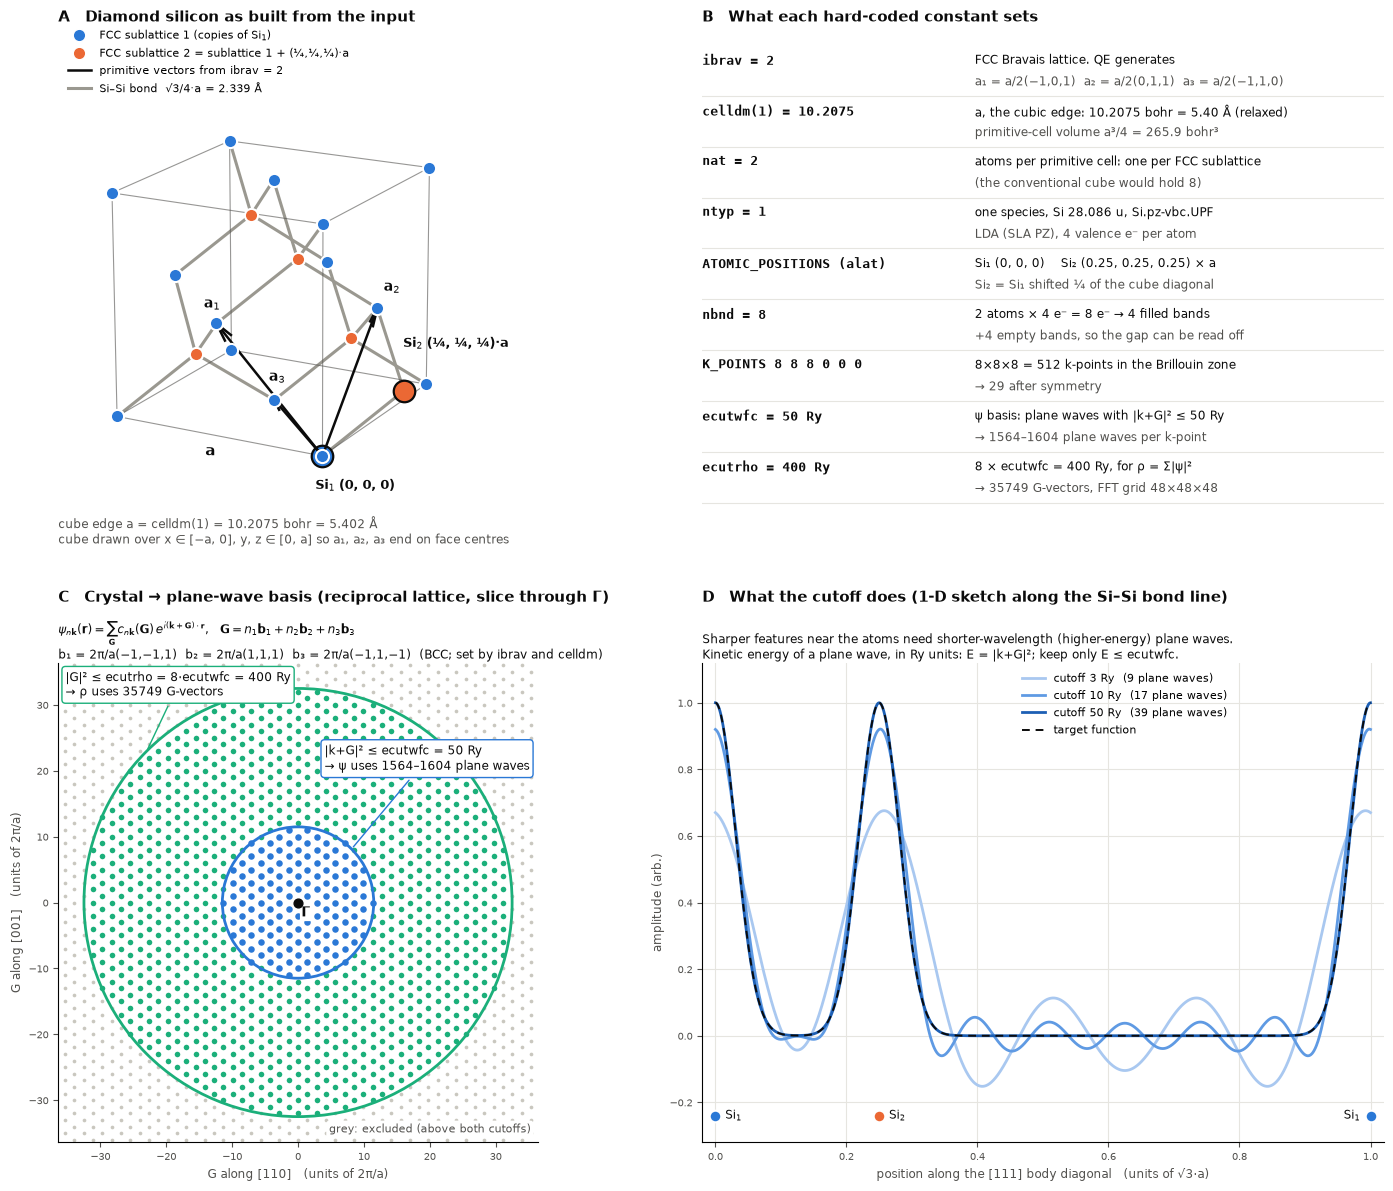

[PASS] plane-wave sets from input constants - 29 k-points, 1564-1604 PW/k, 35749 G for rho


In [40]:
import importlib, si_figure
importlib.reload(si_figure)   # picks up changes to the script without restarting the kernel

fig, pw_counts = si_figure.make_si_figure(a_bohr=10.2075, ecutwfc=50, ecutrho=400, mesh=(8, 8, 8), fft=48, relaxed=True)
plt.show()
check("plane-wave sets from input constants", pw_counts["n_rho"] == 35749 and len(pw_counts["npw_k"]) == 29,
      f"{len(pw_counts['npw_k'])} k-points, {min(pw_counts['npw_k'])}-{max(pw_counts['npw_k'])} PW/k, {pw_counts['n_rho']} G for rho")

### 3.1 Convergence Tests

Each scan changes one setting and compares the result with the last value in the scan. A setting counts as converged within 1 mRy/atom and 0.5 kbar. The base input is the tutorial's (`celldm(1)` = 10.0, shifted k-grid), so its energies differ from the SCF run below. The dashed line marks the value used below.

In [3]:
def si_scan_input(ecut=30, alat=10.0, k=6):
    """SCF input for the tutorial's convergence scans, with pressure switched on."""
    return f'''&CONTROL
  calculation = 'scf',
  prefix = 'scan',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  tstress = .true.
/
&SYSTEM
  ibrav = 2,
  celldm(1) = {alat},
  nat = 2,
  ntyp = 1,
  ecutwfc = {ecut}
/
&ELECTRONS
  mixing_beta = 0.6
/
ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25
K_POINTS (automatic)
  {k} {k} {k} 1 1 1
'''

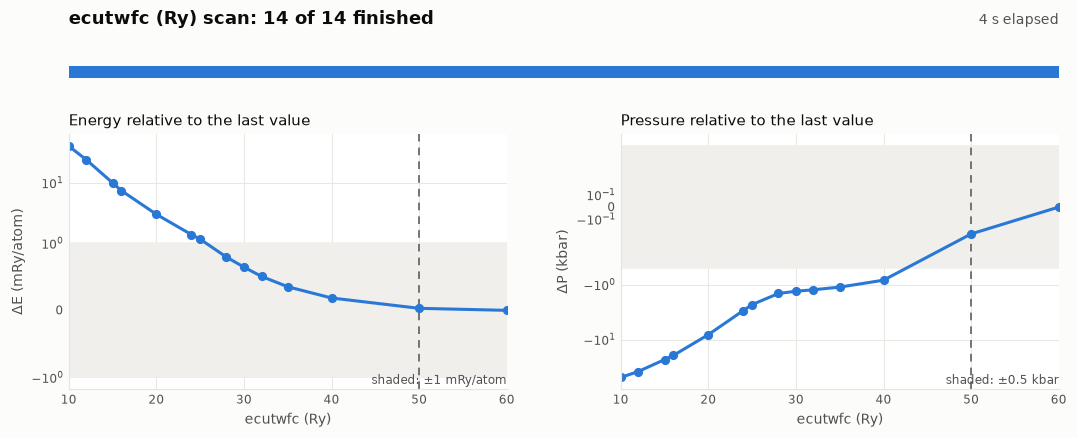

,ecutwfc (Ry),E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,10,-15.768788,40.729,16.74,-48.99,28,0.5
1,12,-15.801961,24.143,27.49,-38.24,28,0.5
2,15,-15.830221,10.013,42.53,-23.20,28,0.8
3,16,-15.835349,7.449,46.23,-19.50,28,0.8
4,20,-15.844213,3.017,57.58,-8.15,28,0.8
5,24,-15.847465,1.391,62.77,-2.96,28,0.8
6,25,-15.847911,1.168,63.42,-2.31,28,0.8
7,28,-15.848660,0.793,64.28,-1.45,28,0.8
8,30,-15.848958,0.644,64.41,-1.32,28,1.1
9,32,-15.849234,0.506,64.49,-1.24,28,1.2


[PASS] ecutwfc (Ry) = 50 converged - ΔE 0.030 mRy/atom, ΔP -0.22 kbar


In [4]:
SI_ECUT_SCAN = scan_pw(SI_RUN / "convergence", "ecut", [10, 12, 15, 16, 20, 24, 25, 28, 30, 32, 35, 40, 50, 60],
                       lambda ecut: si_scan_input(ecut=ecut), "ecutwfc (Ry)", nat=2, chosen=50)

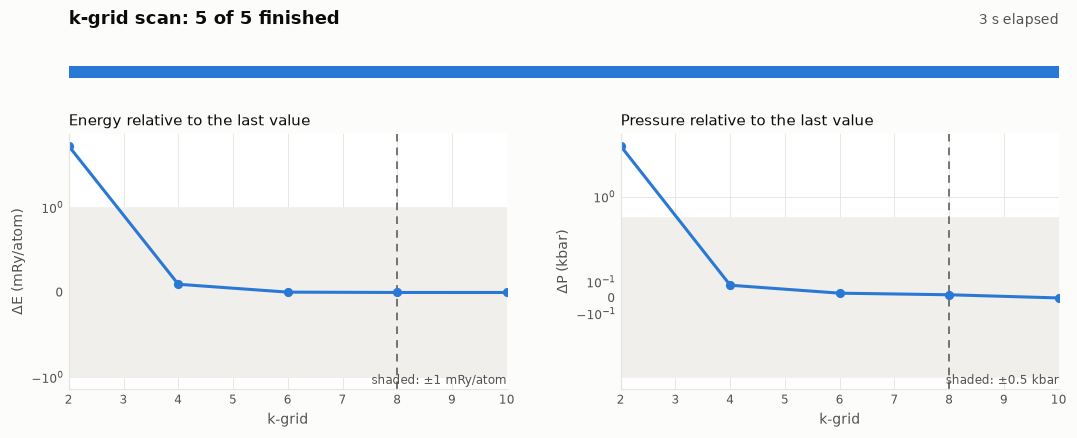

,k-grid,E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,2,-15.836229,6.369,69.52,5.14,2,0.4
1,4,-15.848773,0.097,64.46,0.08,10,0.6
2,6,-15.848958,0.004,64.41,0.03,28,1.1
3,8,-15.848966,0.000,64.40,0.02,60,1.7
4,10,-15.848967,0.000,64.38,0.00,110,2.8


[PASS] k-grid = 8 converged - ΔE 0.000 mRy/atom, ΔP 0.02 kbar


In [5]:
SI_K_SCAN = scan_pw(SI_RUN / "convergence", "k", [2, 4, 6, 8, 10],
                    lambda k: si_scan_input(k=k), "k-grid", nat=2, chosen=8)

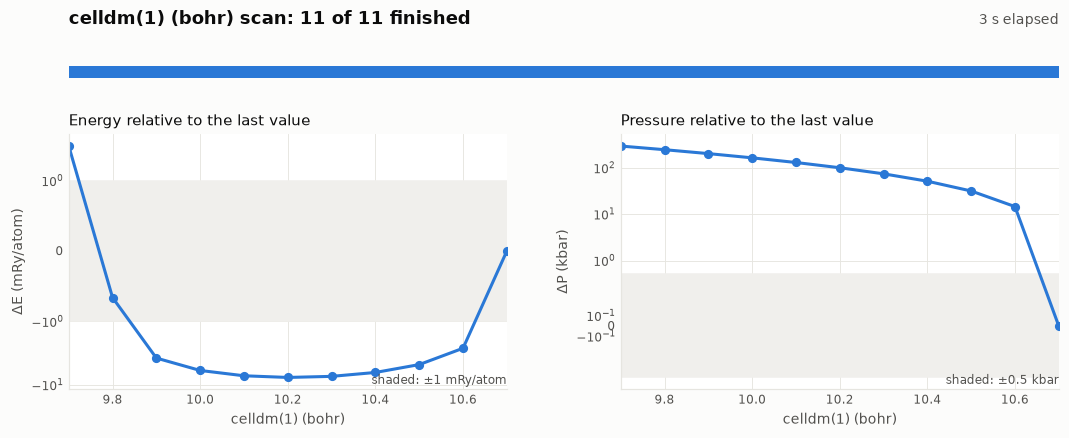

,celldm(1) (bohr),E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,9.7,-15.830067,3.518,195.27,295.09,28,0.8
1,9.8,-15.838425,-0.661,146.32,246.14,28,1.1
2,9.9,-15.844660,-3.778,102.86,202.68,28,1.1
3,10.0,-15.848958,-5.928,64.41,164.23,28,1.1
4,10.1,-15.851482,-7.189,30.45,130.27,28,1.1
5,10.2,-15.852380,-7.638,0.58,100.40,28,1.1
6,10.3,-15.851790,-7.344,-25.58,74.24,28,1.1
7,10.4,-15.849851,-6.374,-48.39,51.43,28,1.1
8,10.5,-15.846678,-4.787,-68.18,31.64,28,1.1
9,10.6,-15.842392,-2.645,-85.24,14.58,28,1.1


a0 = 10.2090 bohr = 5.4024 Å   (experiment 5.431 Å)
B  = 93.9 GPa   (experiment about 98 GPa)
[PASS] LDA a0 in expected range (5.36-5.42 Å) - 5.4024 Å
[PASS] Bulk modulus in expected range (85-105 GPa) - 93.9 GPa


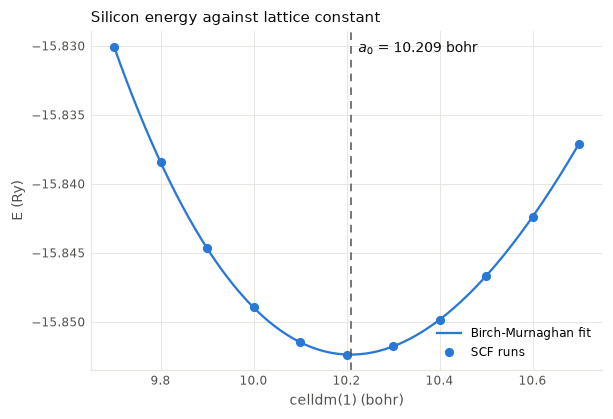

In [6]:
from ase.eos import EquationOfState
from ase.units import Bohr, GPa, Ry

SI_ALAT_SCAN = scan_pw(SI_RUN / "convergence", "alat", [float(a) for a in np.round(np.arange(9.7, 10.71, 0.1), 2)],
                       lambda alat: si_scan_input(alat=alat), "celldm(1) (bohr)", nat=2)

# Birch-Murnaghan fit. For fcc, the volume per primitive cell is a³/4
alats = SI_ALAT_SCAN["celldm(1) (bohr)"].to_numpy()
eos = EquationOfState((alats * Bohr) ** 3 / 4, SI_ALAT_SCAN["E (Ry)"].to_numpy() * Ry, eos="birchmurnaghan")
v0, e0, B = eos.fit()
SI_A0 = (4 * v0) ** (1 / 3) / Bohr
print(f"a0 = {SI_A0:.4f} bohr = {SI_A0 * Bohr:.4f} Å   (experiment 5.431 Å)")
print(f"B  = {B / GPa:.1f} GPa   (experiment about 98 GPa)")
check("LDA a0 in expected range (5.36-5.42 Å)", 5.36 <= SI_A0 * Bohr <= 5.42, f"{SI_A0 * Bohr:.4f} Å")
check("Bulk modulus in expected range (85-105 GPa)", 85 <= B / GPa <= 105, f"{B / GPa:.1f} GPa")

fig, ax = plt.subplots(figsize=(6, 4), dpi=110, facecolor="white")
fine = np.linspace(alats.min(), alats.max(), 300)
ax.plot(fine, eos.func((fine * Bohr) ** 3 / 4, *eos.eos_parameters) / Ry, color=BLUE, linewidth=1.5, label="Birch-Murnaghan fit")
ax.plot(alats, SI_ALAT_SCAN["E (Ry)"], "o", color=BLUE, markersize=5, label="SCF runs")
ax.axvline(SI_A0, color=MUTED, linestyle=(0, (5, 4)), linewidth=1)
ax.annotate(f"$a_0$ = {SI_A0:.3f} bohr", (SI_A0, 1), xycoords=("data", "axes fraction"), xytext=(5, -14),
            textcoords="offset points", fontsize=9, color=INK)
style(ax, "Silicon energy against lattice constant", "celldm(1) (bohr)", "E (Ry)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

### 3.2 Structure Optimization

In [7]:
SI_OPT_INPUT = f'''&CONTROL
  calculation = 'vc-relax',
  prefix = 'silicon_opt',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  etot_conv_thr = 1e-5,
  forc_conv_thr = 1e-4
/
&SYSTEM
  ibrav = 2,
  celldm(1) = 14,
  nat = 2,
  ntyp = 1,
  ecutwfc = 30
/
&ELECTRONS
  conv_thr = 1e-8
/
&IONS
/
&CELL
  cell_dofree = 'ibrav'
/
ATOMIC_SPECIES
  Si 28.0855 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.00 0.00 0.00 0 0 0
  Si 0.25 0.25 0.25 0 0 0
K_POINTS (automatic)
  6 6 6 1 1 1
'''

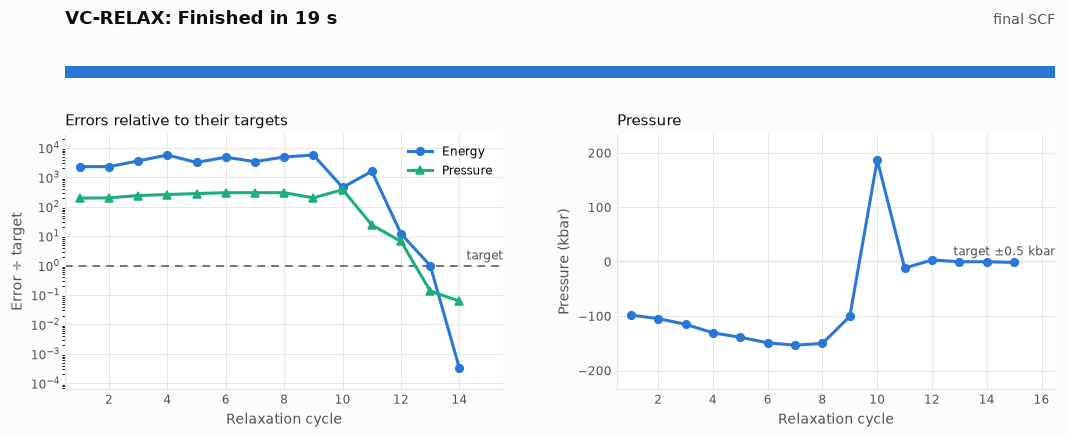

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 19.4 s
[PASS] Relaxation converged
Relaxed lattice parameter: 10.2075 bohr, fitted a0: 10.2090 bohr, used below: 10.2076 bohr
[PASS] Relaxed and fitted lattice parameters agree
[PASS] Lattice parameter used below is within 0.5% of the relaxed one


In [8]:
SI_OPT_OUT = run_pw("pw.opt_silicon.in", SI_OPT_INPUT, SI_RUN)

# The tutorial starts far from the answer on purpose, at 14 bohr
SI_RELAXED_ALAT = relaxed_alat(SI_OPT_OUT)
print(f"Relaxed lattice parameter: {SI_RELAXED_ALAT:.4f} bohr, fitted a0: {SI_A0:.4f} bohr, used below: 10.2076 bohr")
check("Relaxed and fitted lattice parameters agree", abs(SI_RELAXED_ALAT - SI_A0) / SI_A0 < 0.005)
check("Lattice parameter used below is within 0.5% of the relaxed one", abs(SI_RELAXED_ALAT - 10.2076) / 10.2076 < 0.005)

### 3.3 SCF Calculation

In [10]:
SI_SCF_INPUT = f'''&CONTROL
  calculation = 'scf',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&SYSTEM
  ibrav = 2,
  celldm(1) = 10.2075,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  ecutrho = 400,
  nbnd = 8,
!  occupations = 'smearing',
!  smearing = 'gaussian',
!  degauss = 0.005
/
&ELECTRONS
  conv_thr = 1e-8,
  mixing_beta = 0.6
/
ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25
K_POINTS (automatic)
  8 8 8 0 0 0
'''

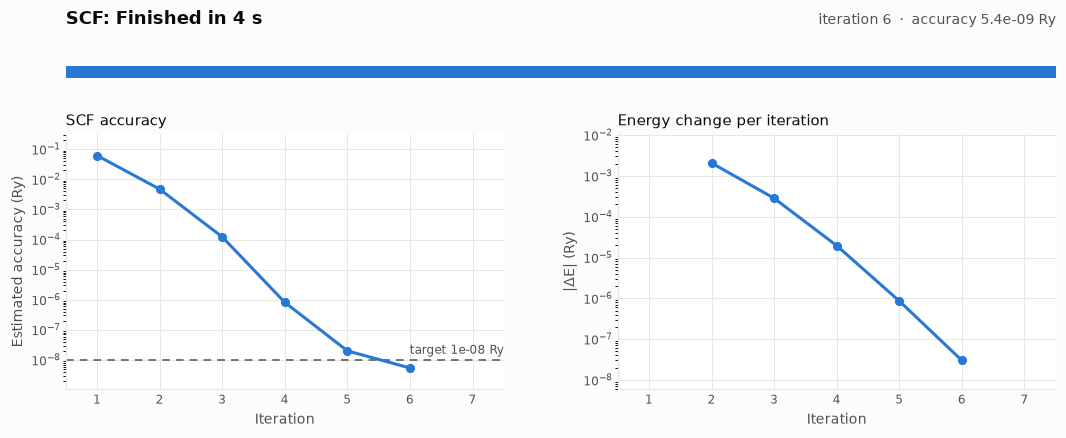

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 4.5 s
[PASS] SCF converged


In [11]:
SI_SCF_OUT = run_pw("pw.scf.silicon.in", SI_SCF_INPUT, SI_RUN)

### 3.4 NSCF and Density of States

The NSCF run uses a denser k-grid and tetrahedra occupations, and `dos.x` then turns its energies into a density of states.

In [12]:
SI_NSCF_INPUT = f'''&CONTROL
  calculation = 'nscf',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&SYSTEM
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  ecutrho = 400,
  nbnd = 8,
  occupations = 'tetrahedra'
/
&ELECTRONS
  conv_thr = 1e-8,
  mixing_beta = 0.6
/
ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25
K_POINTS (automatic)
  12 12 12 0 0 0
'''

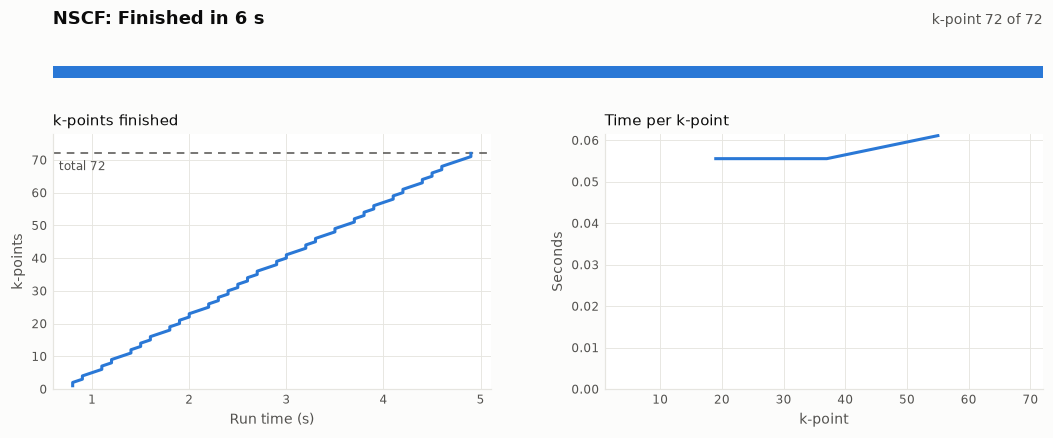

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 6.0 s
[PASS] NSCF finished


In [13]:
SI_NSCF_OUT = run_pw("pw.nscf.silicon.in", SI_NSCF_INPUT, SI_RUN)

In [14]:
SI_DOS_INPUT = f'''&DOS
  prefix = 'silicon'
  outdir = './tmp/'
  fildos = 'si_dos.dat'
  emin = -9.0
  emax = 16.0
  DeltaE = 0.02
/
'''
(SI_RUN / "pw.dos.silicon.in").write_text(SI_DOS_INPUT)

# Equivalent of:  dos.x < pw.dos.silicon.in > pw.dos.silicon.out
run_qe(DOS, SI_RUN / "pw.dos.silicon.in")
check("dos.x wrote data", (SI_RUN / "si_dos.dat").exists())

[PASS] dos.x wrote data


Band gap from the DOS: 0.52 eV


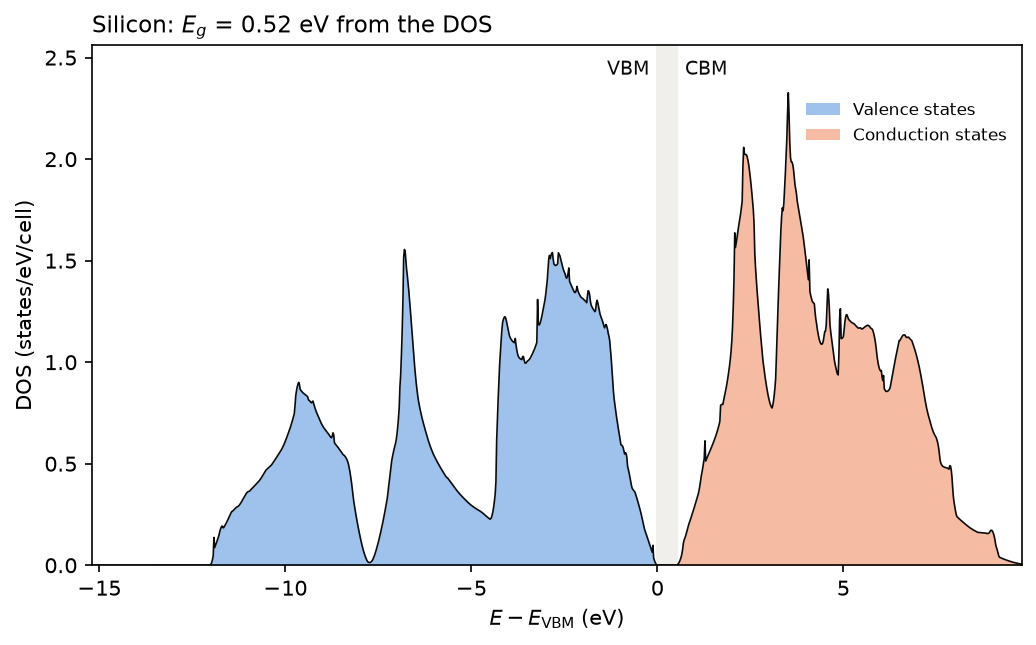

In [15]:
SI_DOS_GAP = plot_dos(SI_RUN, "si_dos.dat", SI_NSCF_OUT, "Silicon")

### 3.5 Band Structure Calculation and Plotting

In [16]:
SI_BAND_INPUT = f'''&control
  calculation = 'bands',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&system
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  ecutrho = 400,
  nbnd = 8
 /
&electrons
  conv_thr = 1e-8,
  mixing_beta = 0.6
 /
ATOMIC_SPECIES
  Si 28.086  Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.00 0.00 0.00
  Si 0.25 0.25 0.25
K_POINTS {{crystal_b}}
5
  0.0000 0.5000 0.0000 20  !L
  0.0000 0.0000 0.0000 30  !G
  -0.500 0.0000 -0.500 10  !X
  -0.375 0.2500 -0.375 30  !U
  0.0000 0.0000 0.0000 20  !G
'''

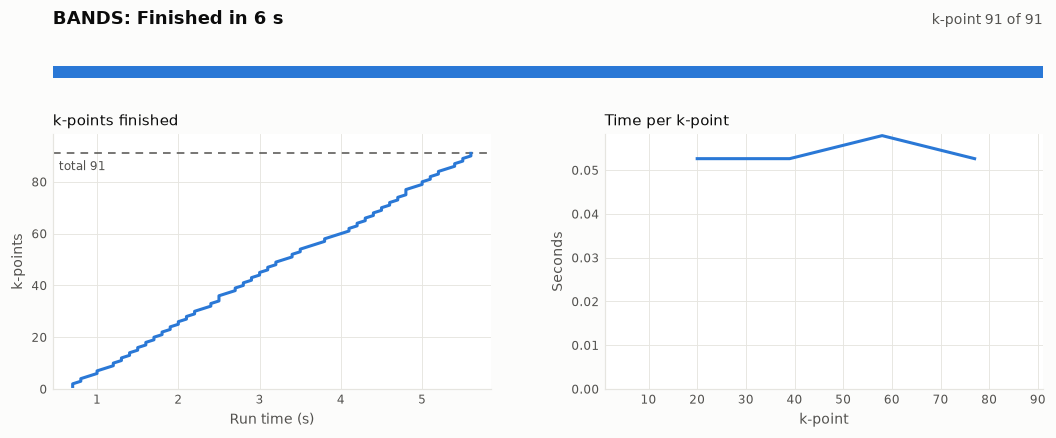

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 5.9 s
[PASS] Bands finished


In [17]:
SI_BAND_OUT = run_pw("pw.scf.bg_silicon.in", SI_BAND_INPUT, SI_RUN)

In [18]:
SI_POST = f'''&BANDS
  prefix = 'silicon'
  outdir = './tmp/'
  filband = 'si_bands.dat'
/
'''
(SI_RUN / "pw.scf.pp_silicon.in").write_text(SI_POST)

# Equivalent of:  bands.x < pw.scf.pp_silicon.in > pw.scf.pp_silicon.out
run_qe(BANDS, SI_RUN / "pw.scf.pp_silicon.in")
check("bands.x wrote data", (SI_RUN / "si_bands.dat.gnu").exists())

[PASS] bands.x wrote data


Band gap along this path: 0.50 eV (indirect)
  VBM at Γ, CBM at Γ–X
  Smallest direct gap: 2.57 eV


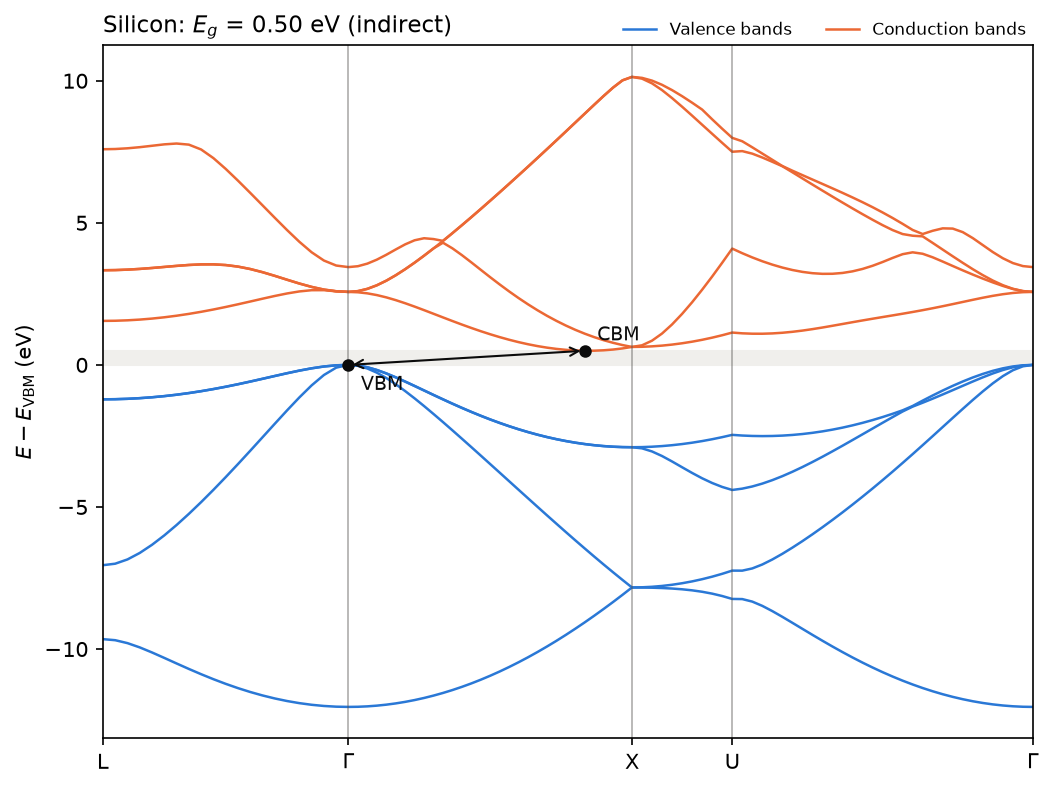

Gap comparison: 0.50 eV from bands, 0.52 eV from the DOS


In [19]:
SI_GAP = plot_band_gap(SI_RUN, "si_bands.dat", SI_RUN / "pw.scf.pp_silicon.out", SI_SCF_OUT,
                       "Silicon", ["L", r"$\Gamma$", "X", "U", r"$\Gamma$"])
print(f"Gap comparison: {SI_GAP:.2f} eV from bands, {SI_DOS_GAP:.2f} eV from the DOS")

## 4. α-Quartz

The stable form of quartz at room temperature: trigonal, space group P3₂21, 9 atoms per cell. The starting cell and positions are room-temperature experimental values.

Settings for both forms of quartz. The convergence tests in this section show the evidence for the first two:

| Setting | Value | Why |
|---|---|---|
| `ecutwfc` / `ecutrho` | 80 / 640 Ry | Pressure is within 0.5 kbar of the 100 Ry value; at 60 Ry it's 3 kbar off |
| k-grid | 3×3×3 | Within 0.2 kbar and 0.03 mRy of 6×6×6 |
| `nbnd` | 32 | 24 filled bands plus 8 empty ones |
| NSCF k-grid | 6×6×6 | Denser, for a smooth DOS |
| `mixing_beta` | 0.5 | About 14 SCF iterations instead of 24, with the same energy |
| `etot_conv_thr` / `forc_conv_thr` | 1e-5 / 1e-4 | Tight enough for a 9-atom cell |

### 4.1 Convergence Tests

Each scan changes one setting and compares the result with the last value in the scan. A setting counts as converged within 1 mRy/atom and 0.5 kbar. Pressure matters most here, because it drives the structure optimization. `ecutrho` stays at 8 × `ecutwfc`, and the dashed line marks the value used below.

In [20]:
def alpha_scan_input(ecut=80, k=3):
    """SCF input for the convergence scans, at the experimental structure, with pressure switched on."""
    return f'''&CONTROL
  calculation= 'scf',
  prefix= 'scan',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  tstress= .true.
/

&SYSTEM
  ibrav= 4,
  celldm(1)= 9.28555,
  celldm(3)= 1.09992,
  nat= 9,
  ntyp= 2,
  ecutwfc= {ecut},
  ecutrho= {8 * ecut},
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
  Si 0.46970 0.00000 0.666666667
  Si 0.00000 0.46970 0.333333333
  Si 0.53030 0.53030 0.00000
  O  0.41350 0.26690 0.78580
  O  0.73310 0.14660 0.452466667
  O  0.85340 0.58650 0.119133333
  O  0.26690 0.41350 0.21420
  O  0.14660 0.73310 0.547533333
  O  0.58650 0.85340 0.880866667

K_POINTS (automatic)
  {k} {k} {k} 0 0 0
'''

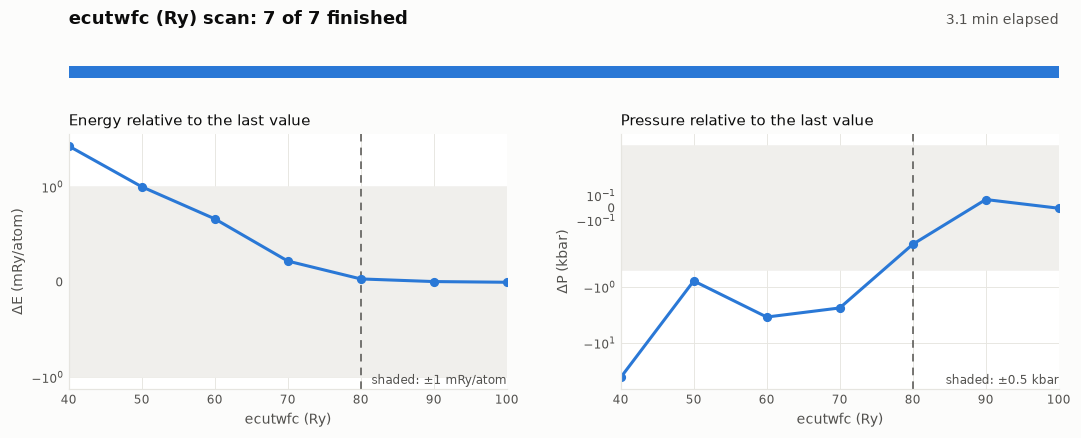

,ecutwfc (Ry),E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,40,-229.660383,3.012,41.27,-40.80,7,38.0
1,50,-229.678418,1.008,81.30,-0.77,7,58.4
2,60,-229.681494,0.666,78.67,-3.40,7,89.0
3,70,-229.685486,0.223,79.73,-2.34,7,66.5
4,80,-229.687176,0.035,81.78,-0.29,7,82.8
5,90,-229.687425,0.007,82.14,0.07,7,105.5
6,100,-229.687490,0.000,82.07,0.00,7,120.1


[PASS] ecutwfc (Ry) = 80 converged - ΔE 0.035 mRy/atom, ΔP -0.29 kbar


In [21]:
ALPHA_ECUT_SCAN = scan_pw(ALPHA_RUN / "convergence", "ecut", [40, 50, 60, 70, 80, 90, 100],
                        lambda ecut: alpha_scan_input(ecut=ecut), "ecutwfc (Ry)", nat=9, chosen=80)

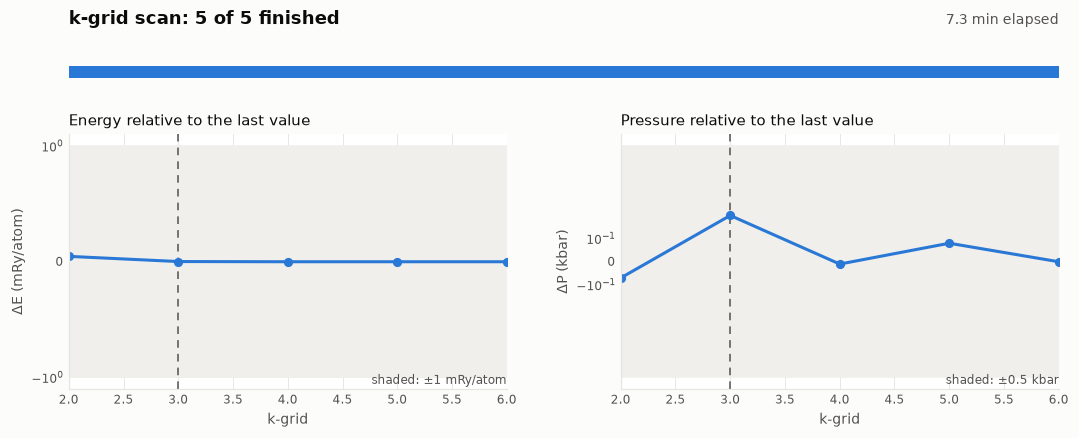

,k-grid,E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,2,-229.686773,0.046,81.51,-0.07,4,61.7
1,3,-229.687176,0.002,81.78,0.20,7,81.6
2,4,-229.687192,-0.000,81.57,-0.01,13,145.2
3,5,-229.687191,0.000,81.66,0.08,19,204.3
4,6,-229.687192,0.000,81.58,0.00,34,377.9


[PASS] k-grid = 3 converged - ΔE 0.002 mRy/atom, ΔP 0.20 kbar


In [22]:
ALPHA_K_SCAN = scan_pw(ALPHA_RUN / "convergence", "k", [2, 3, 4, 5, 6],
                     lambda k: alpha_scan_input(k=k), "k-grid", nat=9, chosen=3)

### 4.2 Structure Optimization

In [23]:
ALPHA_RELAX_INPUT = f'''&CONTROL
  calculation= 'vc-relax',
  prefix= 'sio2_alpha',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  etot_conv_thr= 1e-5,
  forc_conv_thr= 1e-4,
  nstep= 100
/

&SYSTEM
  ibrav= 4,
  celldm(1)= 9.28555,
  celldm(3)= 1.09992,
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

&IONS
/

&CELL
  cell_dofree= 'ibrav'
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
  Si 0.46970 0.00000 0.666666667
  Si 0.00000 0.46970 0.333333333
  Si 0.53030 0.53030 0.00000
  O  0.41350 0.26690 0.78580
  O  0.73310 0.14660 0.452466667
  O  0.85340 0.58650 0.119133333
  O  0.26690 0.41350 0.21420
  O  0.14660 0.73310 0.547533333
  O  0.58650 0.85340 0.880866667

K_POINTS (automatic)
  3 3 3 0 0 0
'''

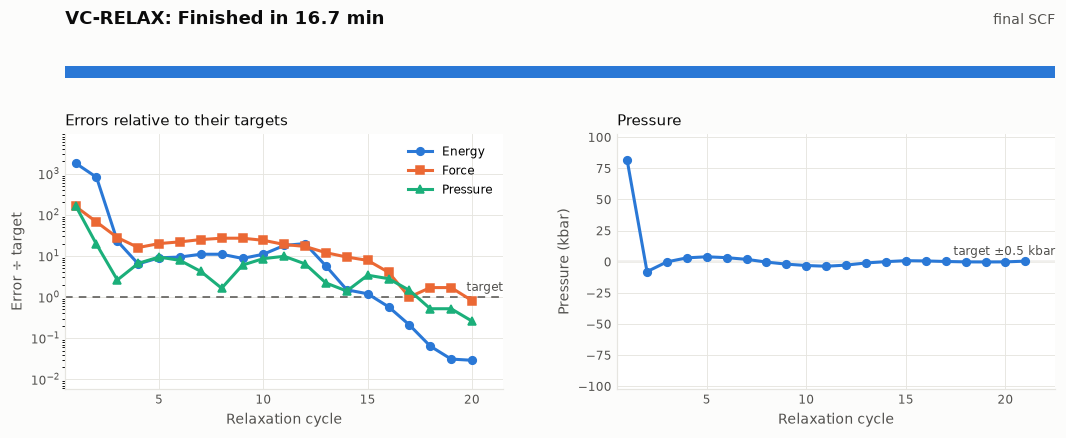

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 999.8 s
[PASS] Relaxation converged
Parameter               Experiment     Relaxed  Difference
a (Å)                       4.9137      5.0344      +2.46%
c (Å)                       5.4047      5.5231      +2.19%
c/a                         1.0999      1.0971      -0.26%
Volume per SiO2 (Å³)       37.6702     40.4095      +7.27%
[PASS] a and c within 3% of experiment
[PASS] Crystal symmetry kept - 6 operations


In [24]:
ALPHA_EXPERIMENT = {"a": 4.9137, "c": 5.4047}   # Å

ALPHA_RELAX_OUT = run_pw("pw.scf.vc_sio2_alpha.in", ALPHA_RELAX_INPUT, ALPHA_RUN)

# Later α-quartz steps use this relaxed cell and these relaxed atomic positions
ALPHA_RELAXED = relaxed_hexagonal(ALPHA_RELAX_OUT)
check_parameters(ALPHA_RELAXED, ALPHA_EXPERIMENT, ALPHA_RELAX_OUT, symmetry_ops=6)

### 4.3 SCF Calculation

In [25]:
ALPHA_SCF_INPUT = f'''&CONTROL
  calculation= 'scf',
  restart_mode= 'from_scratch',
  prefix= 'sio2_alpha',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {ALPHA_RELAXED['a']:.6f},
  celldm(3)= {ALPHA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{ALPHA_RELAXED['positions']}

K_POINTS (automatic)
  3 3 3 0 0 0
'''

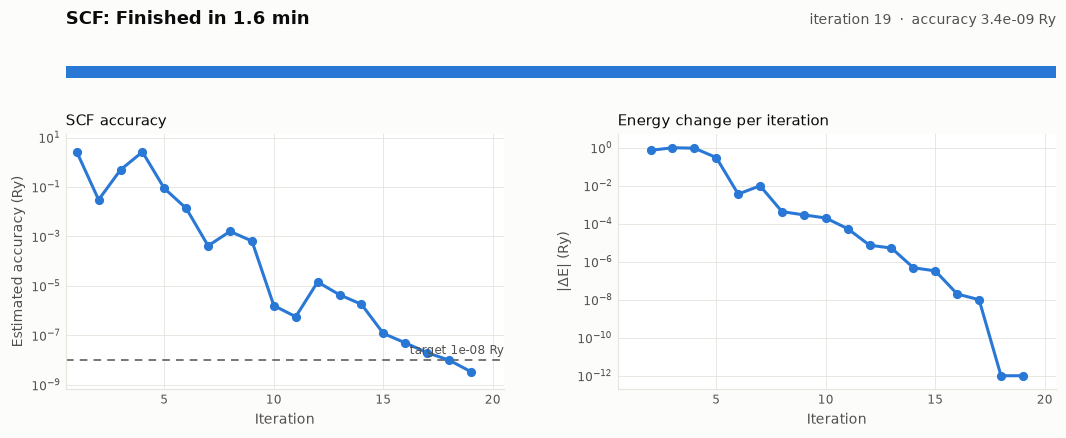

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 96.9 s
[PASS] SCF converged


In [26]:
ALPHA_SCF_OUT = run_pw("pw.scf.sio2_alpha.in", ALPHA_SCF_INPUT, ALPHA_RUN)

#### What the final α-quartz input describes

This figure explains the input the band gap comes from: the relaxed cell and atom positions from 4.2, with the settings from 4.1. It sits here because the relaxed values don't exist until the structure optimization has run. Every setting is read from `ALPHA_SCF_INPUT`, and the band calculation reuses the same structure and cutoffs.

- **A** shows the relaxed cell built from `ibrav = 4`, `celldm(1)`, `celldm(3)` and `ATOMIC_POSITIONS`. Each Si sits inside a tetrahedron of four O, and each O joins two Si. Hollow atoms belong to neighbouring cells.
- **B** maps every hard-coded constant to its meaning.
- **C** shows the plane-wave basis, as in the silicon figure. Ultrasoft pseudopotentials add sharp charges to the density, so `ecutrho` is well above the default 4 × `ecutwfc`.
- **D** is a 1-D sketch of why a cutoff works, along a straightened Si–O–Si chain. It's an illustration, not calculated data.

The cell below checks the figure's k-point, plane-wave and G-vector counts against the SCF output above. The code is in [sio2_figure.py](sio2_figure.py).

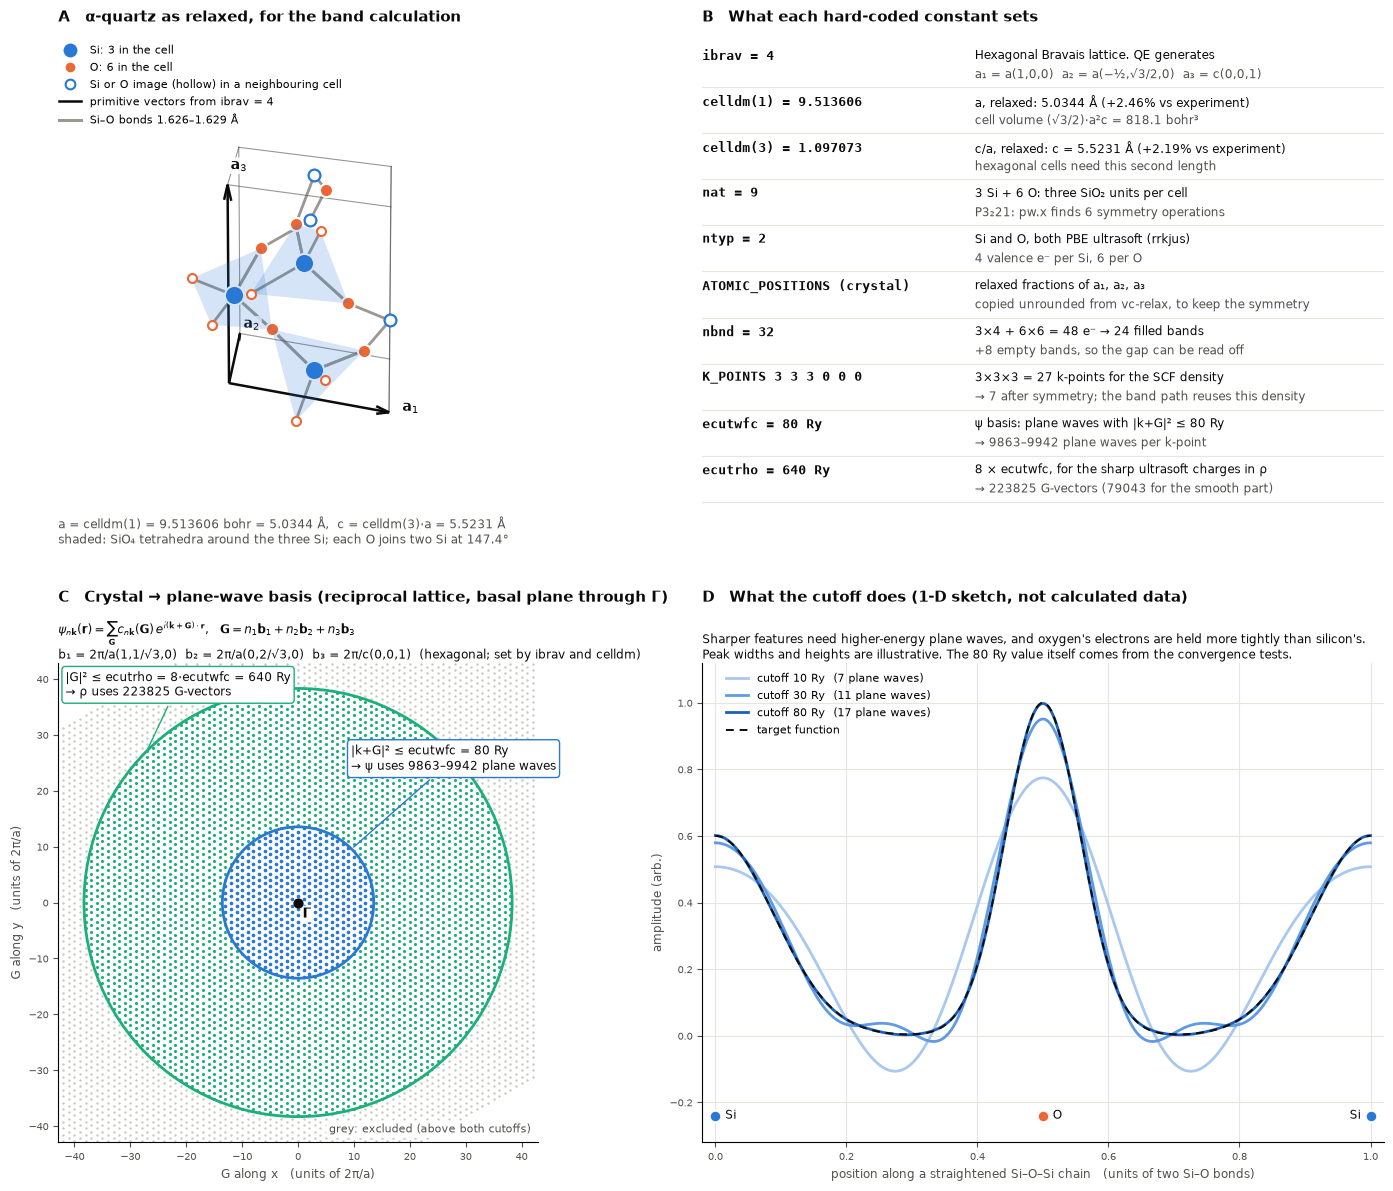

[PASS] figure matches the pw.x output - 7 k-points, 9863-9942 PW/k, 223825 G for rho


In [41]:
import importlib, sio2_figure
importlib.reload(sio2_figure)   # picks up changes to the script without restarting the kernel

fig, pw_counts = sio2_figure.make_sio2_figure("alpha", ALPHA_SCF_INPUT, ALPHA_SCF_OUT)
plt.show()
check("figure matches the pw.x output", not pw_counts["differences"],
      f"{len(pw_counts['npw_k'])} k-points, {min(pw_counts['npw_k'])}-{max(pw_counts['npw_k'])} PW/k, {pw_counts['n_rho']} G for rho")

### 4.4 NSCF and Density of States

The NSCF run uses a denser k-grid and tetrahedra occupations, and `dos.x` then turns its energies into a density of states.

In [27]:
ALPHA_NSCF_INPUT = f'''&CONTROL
  calculation= 'nscf',
  restart_mode= 'from_scratch',
  prefix= 'sio2_alpha',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {ALPHA_RELAXED['a']:.6f},
  celldm(3)= {ALPHA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32,
  occupations= 'tetrahedra'
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{ALPHA_RELAXED['positions']}

K_POINTS (automatic)
  6 6 6 0 0 0
'''

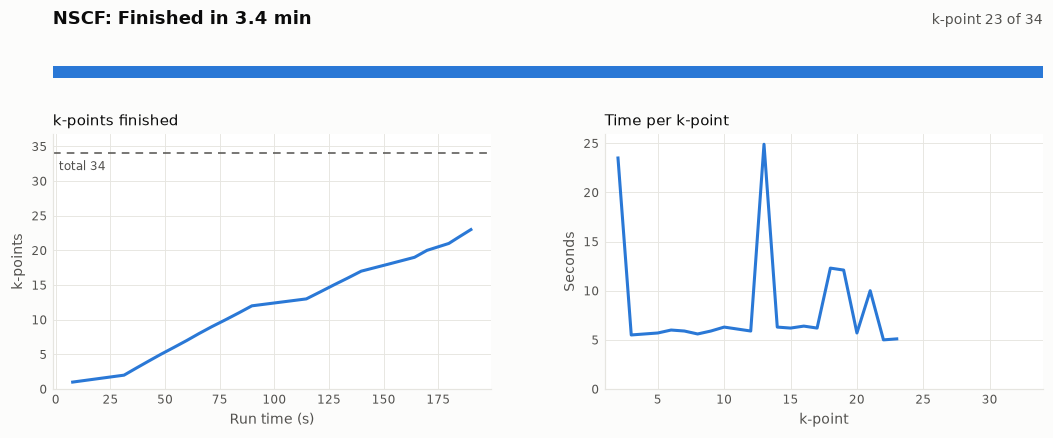

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 201.5 s
[PASS] NSCF finished


In [28]:
ALPHA_NSCF_OUT = run_pw("pw.nscf.sio2_alpha.in", ALPHA_NSCF_INPUT, ALPHA_RUN)

In [29]:
ALPHA_DOS_INPUT = f'''&DOS
  prefix = 'sio2_alpha'
  outdir = './tmp/'
  fildos = 'sio2_alpha_dos.dat'
  DeltaE = 0.02
/
'''
(ALPHA_RUN / "pw.dos.sio2_alpha.in").write_text(ALPHA_DOS_INPUT)

# Equivalent of:  dos.x < pw.dos.sio2_alpha.in > pw.dos.sio2_alpha.out
run_qe(DOS, ALPHA_RUN / "pw.dos.sio2_alpha.in")
check("dos.x wrote data", (ALPHA_RUN / "sio2_alpha_dos.dat").exists())

[PASS] dos.x wrote data


Band gap from the DOS: 5.70 eV


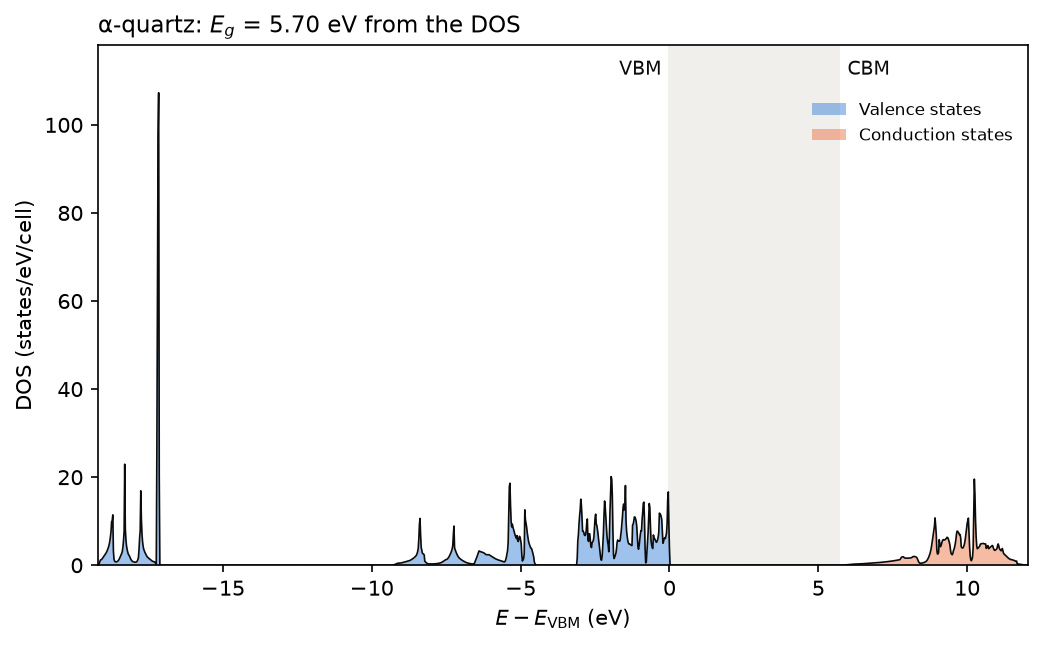

In [30]:
ALPHA_DOS_GAP = plot_dos(ALPHA_RUN, "sio2_alpha_dos.dat", ALPHA_NSCF_OUT, "α-quartz")

### 4.5 Band Structure Calculation and Plotting

In [31]:
ALPHA_BAND_INPUT = f'''&CONTROL
  calculation= 'bands',
  restart_mode= 'from_scratch',
  prefix= 'sio2_alpha',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {ALPHA_RELAXED['a']:.6f},
  celldm(3)= {ALPHA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{ALPHA_RELAXED['positions']}

K_POINTS {{crystal_b}}
8
  0.00000 0.00000 0.00000 14  !G
  0.50000 0.00000 0.00000 8   !M
  0.33333 0.33333 0.00000 16  !K
  0.00000 0.00000 0.00000 11  !G
  0.00000 0.00000 0.50000 14  !A
  0.50000 0.00000 0.50000 8   !L
  0.33333 0.33333 0.50000 16  !H
  0.00000 0.00000 0.50000 1   !A
'''

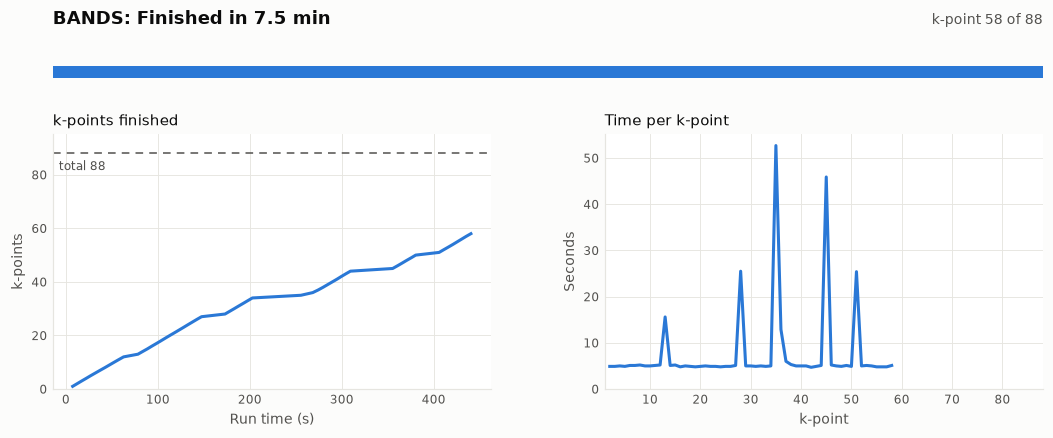

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 452.3 s
[PASS] Bands finished


In [32]:
ALPHA_BAND_OUT = run_pw("pw.scf.bg_sio2_alpha.in", ALPHA_BAND_INPUT, ALPHA_RUN)

In [33]:
# lsym = .false. skips the optional symmetry labels, which crash bands.x for β-quartz
ALPHA_POST = f'''&BANDS
  prefix = 'sio2_alpha'
  outdir = './tmp/'
  filband = 'sio2_alpha_bands.dat'
  lsym = .false.
/
'''
(ALPHA_RUN / "pw.scf.pp_sio2_alpha.in").write_text(ALPHA_POST)

# Equivalent of:  bands.x < pw.scf.pp_sio2_alpha.in > pw.scf.pp_sio2_alpha.out
run_qe(BANDS, ALPHA_RUN / "pw.scf.pp_sio2_alpha.in")
check("bands.x wrote data", (ALPHA_RUN / "sio2_alpha_bands.dat.gnu").exists())

[PASS] bands.x wrote data


Band gap along this path: 5.66 eV (indirect)
  VBM at K, CBM at Γ
  Smallest direct gap: 5.96 eV


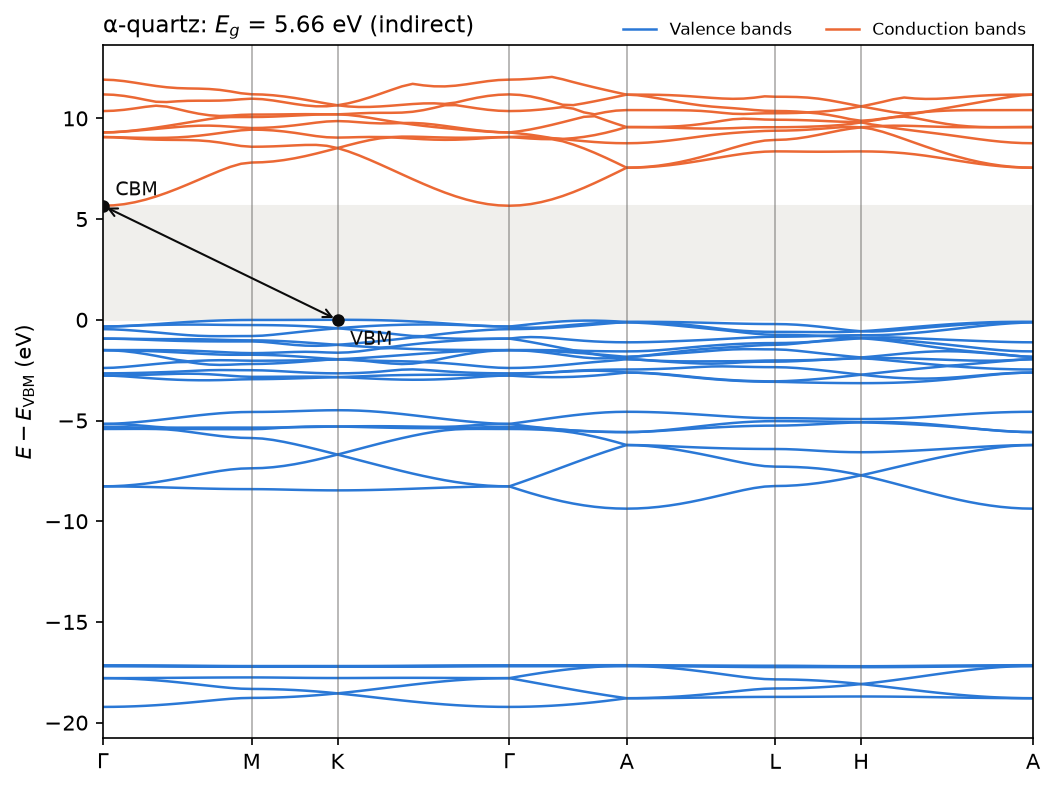

Gap comparison: 5.66 eV from bands, 5.70 eV from the DOS


In [34]:
ALPHA_GAP = plot_band_gap(ALPHA_RUN, "sio2_alpha_bands.dat", ALPHA_RUN / "pw.scf.pp_sio2_alpha.out", ALPHA_SCF_OUT,
                        "α-quartz", [r"$\Gamma$", "M", "K", r"$\Gamma$", "A", "L", "H", "A"])
print(f"Gap comparison: {ALPHA_GAP:.2f} eV from bands, {ALPHA_DOS_GAP:.2f} eV from the DOS")

## 5. β-Quartz

The high-temperature form of quartz, stable above about 573 °C: hexagonal, space group P6₂22, 9 atoms per cell. It uses the same settings as α-quartz.

The starting values are high-temperature experimental ones, but `vc-relax` works at 0 K, where β-quartz isn't the stable form. It stays β-quartz here only because QE keeps the starting symmetry, so compare its relaxed cell with experiment less strictly than α-quartz's.

### 5.1 Convergence Tests

Each scan changes one setting and compares the result with the last value in the scan. A setting counts as converged within 1 mRy/atom and 0.5 kbar. Pressure matters most here, because it drives the structure optimization. `ecutrho` stays at 8 × `ecutwfc`, and the dashed line marks the value used below.

In [42]:
def beta_scan_input(ecut=80, k=3):
    """SCF input for the convergence scans, at the experimental structure, with pressure switched on."""
    return f'''&CONTROL
  calculation= 'scf',
  prefix= 'scan',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  tstress= .true.
/

&SYSTEM
  ibrav= 4,
  celldm(1)= 9.44202,
  celldm(3)= 1.09168,
  nat= 9,
  ntyp= 2,
  ecutwfc= {ecut},
  ecutrho= {8 * ecut},
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
  Si 0.50000 0.00000 0.00000
  Si 0.00000 0.50000 0.666666667
  Si 0.50000 0.50000 0.333333333
  O  0.20720 0.41440 0.50000
  O  0.58560 0.79280 0.166666667
  O  0.20720 0.79280 0.833333333
  O  0.79280 0.58560 0.50000
  O  0.41440 0.20720 0.166666667
  O  0.79280 0.20720 0.833333333

K_POINTS (automatic)
  {k} {k} {k} 0 0 0
'''

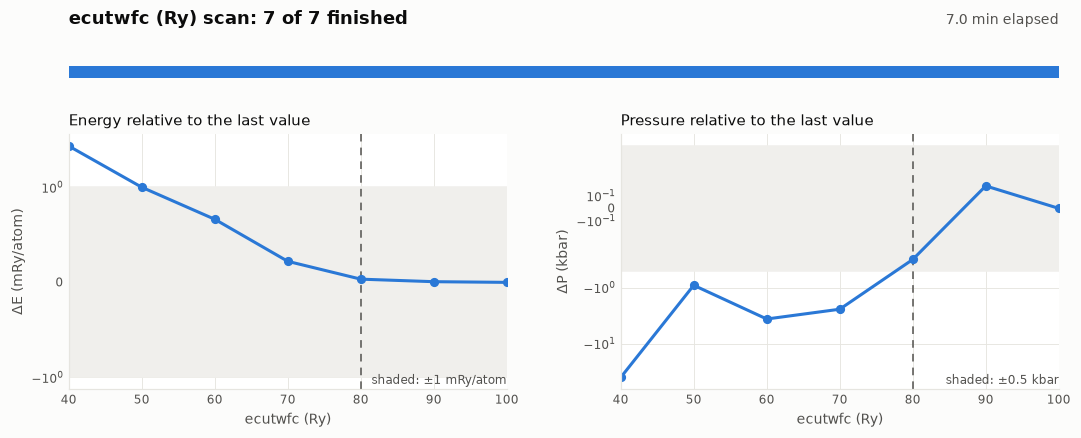

,ecutwfc (Ry),E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,40,-229.644025,3.033,95.70,-39.97,6,59.1
1,50,-229.662320,1.001,134.76,-0.91,6,108.2
2,60,-229.665355,0.663,132.04,-3.63,6,95.2
3,70,-229.669336,0.221,133.24,-2.43,6,149.9
4,80,-229.671023,0.034,135.26,-0.41,6,153.7
5,90,-229.671262,0.007,135.85,0.18,6,223.1
6,100,-229.671326,0.000,135.67,0.00,6,313.8


[PASS] ecutwfc (Ry) = 80 converged - ΔE 0.034 mRy/atom, ΔP -0.41 kbar


In [43]:
BETA_ECUT_SCAN = scan_pw(BETA_RUN / "convergence", "ecut", [40, 50, 60, 70, 80, 90, 100],
                        lambda ecut: beta_scan_input(ecut=ecut), "ecutwfc (Ry)", nat=9, chosen=80)

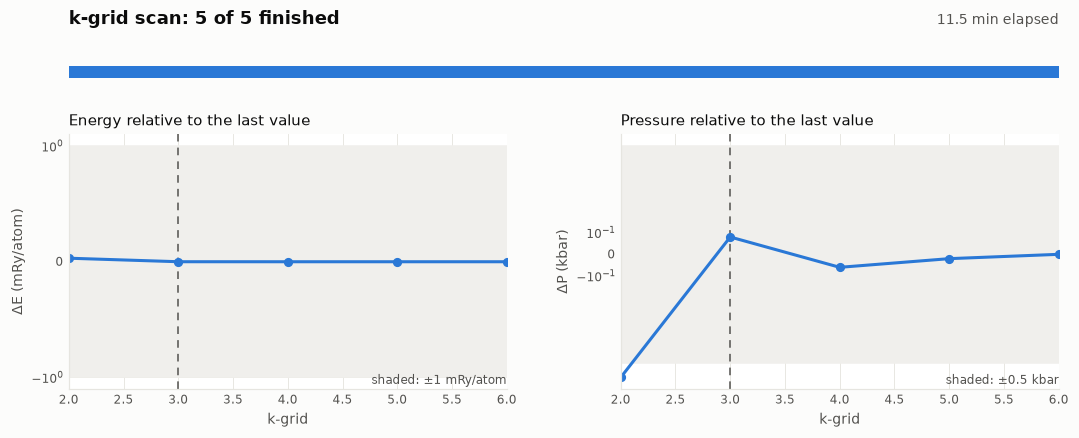

,k-grid,E (Ry),ΔE (mRy/atom),P (kbar),ΔP (kbar),k-points,Time (s)
0,2,-229.670749,0.031,134.47,-0.71,4,107.8
1,3,-229.671023,0.000,135.26,0.08,6,162.0
2,4,-229.671024,-0.000,135.12,-0.06,12,254.5
3,5,-229.671024,0.000,135.16,-0.02,15,294.0
4,6,-229.671024,0.000,135.18,0.00,28,580.9


[PASS] k-grid = 3 converged - ΔE 0.000 mRy/atom, ΔP 0.08 kbar


In [44]:
BETA_K_SCAN = scan_pw(BETA_RUN / "convergence", "k", [2, 3, 4, 5, 6],
                     lambda k: beta_scan_input(k=k), "k-grid", nat=9, chosen=3)

### 5.2 Structure Optimization

In [45]:
BETA_RELAX_INPUT = f'''&CONTROL
  calculation= 'vc-relax',
  prefix= 'sio2_beta',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  etot_conv_thr= 1e-5,
  forc_conv_thr= 1e-4,
  nstep= 100
/

&SYSTEM
  ibrav= 4,
  celldm(1)= 9.44202,
  celldm(3)= 1.09168,
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

&IONS
/

&CELL
  cell_dofree= 'ibrav'
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
  Si 0.50000 0.00000 0.00000
  Si 0.00000 0.50000 0.666666667
  Si 0.50000 0.50000 0.333333333
  O  0.20720 0.41440 0.50000
  O  0.58560 0.79280 0.166666667
  O  0.20720 0.79280 0.833333333
  O  0.79280 0.58560 0.50000
  O  0.41440 0.20720 0.166666667
  O  0.79280 0.20720 0.833333333

K_POINTS (automatic)
  3 3 3 0 0 0
'''

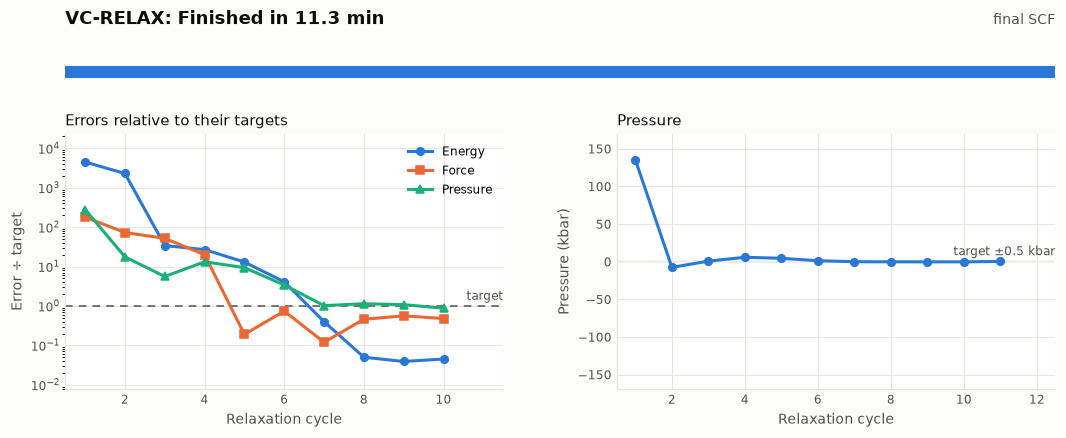

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 678.9 s
[PASS] Relaxation converged
Parameter               Experiment     Relaxed  Difference
a (Å)                       4.9965      5.1095      +2.26%
c (Å)                       5.4546      5.5950      +2.57%
c/a                         1.0917      1.0950      +0.31%
Volume per SiO2 (Å³)       39.3101     42.1661      +7.27%
[PASS] a and c within 3% of experiment
[PASS] Crystal symmetry kept - 12 operations


In [46]:
BETA_EXPERIMENT = {"a": 4.9965, "c": 5.4546}   # Å

BETA_RELAX_OUT = run_pw("pw.scf.vc_sio2_beta.in", BETA_RELAX_INPUT, BETA_RUN)

# Later β-quartz steps use this relaxed cell and these relaxed atomic positions
BETA_RELAXED = relaxed_hexagonal(BETA_RELAX_OUT)
check_parameters(BETA_RELAXED, BETA_EXPERIMENT, BETA_RELAX_OUT, symmetry_ops=12)

### 5.3 SCF Calculation

In [47]:
BETA_SCF_INPUT = f'''&CONTROL
  calculation= 'scf',
  restart_mode= 'from_scratch',
  prefix= 'sio2_beta',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {BETA_RELAXED['a']:.6f},
  celldm(3)= {BETA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{BETA_RELAXED['positions']}

K_POINTS (automatic)
  3 3 3 0 0 0
'''

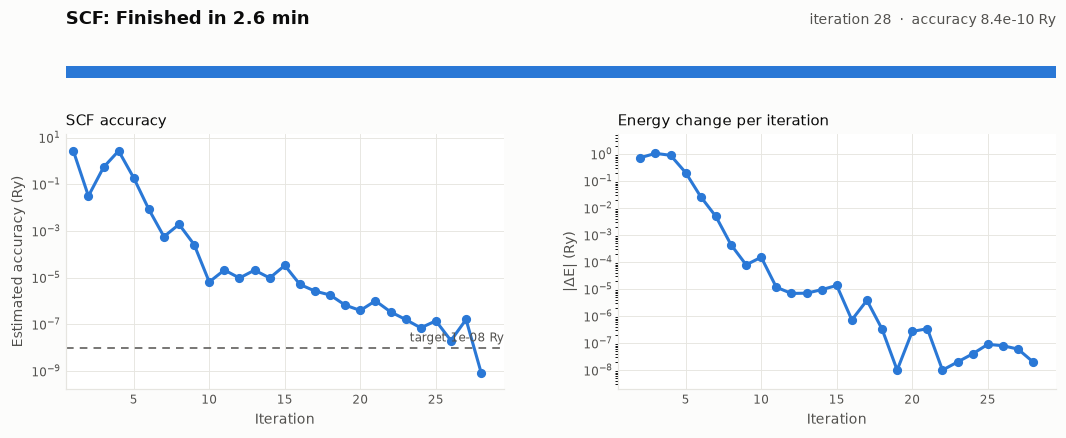

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 156.1 s
[PASS] SCF converged


In [48]:
BETA_SCF_OUT = run_pw("pw.scf.sio2_beta.in", BETA_SCF_INPUT, BETA_RUN)

#### What the final β-quartz input describes

This figure explains the input the band gap comes from: the relaxed cell and atom positions from 5.2, with the settings from 5.1. It sits here because the relaxed values don't exist until the structure optimization has run. Every setting is read from `BETA_SCF_INPUT`, and the band calculation reuses the same structure and cutoffs.

- **A** shows the relaxed cell built from `ibrav = 4`, `celldm(1)`, `celldm(3)` and `ATOMIC_POSITIONS`. Each Si sits inside a tetrahedron of four O, and each O joins two Si. Hollow atoms belong to neighbouring cells.
- **B** maps every hard-coded constant to its meaning.
- **C** shows the plane-wave basis, as in the silicon figure. Ultrasoft pseudopotentials add sharp charges to the density, so `ecutrho` is well above the default 4 × `ecutwfc`.
- **D** is a 1-D sketch of why a cutoff works, along a straightened Si–O–Si chain. It's an illustration, not calculated data.

The cell below checks the figure's k-point, plane-wave and G-vector counts against the SCF output above. The code is in [sio2_figure.py](sio2_figure.py).

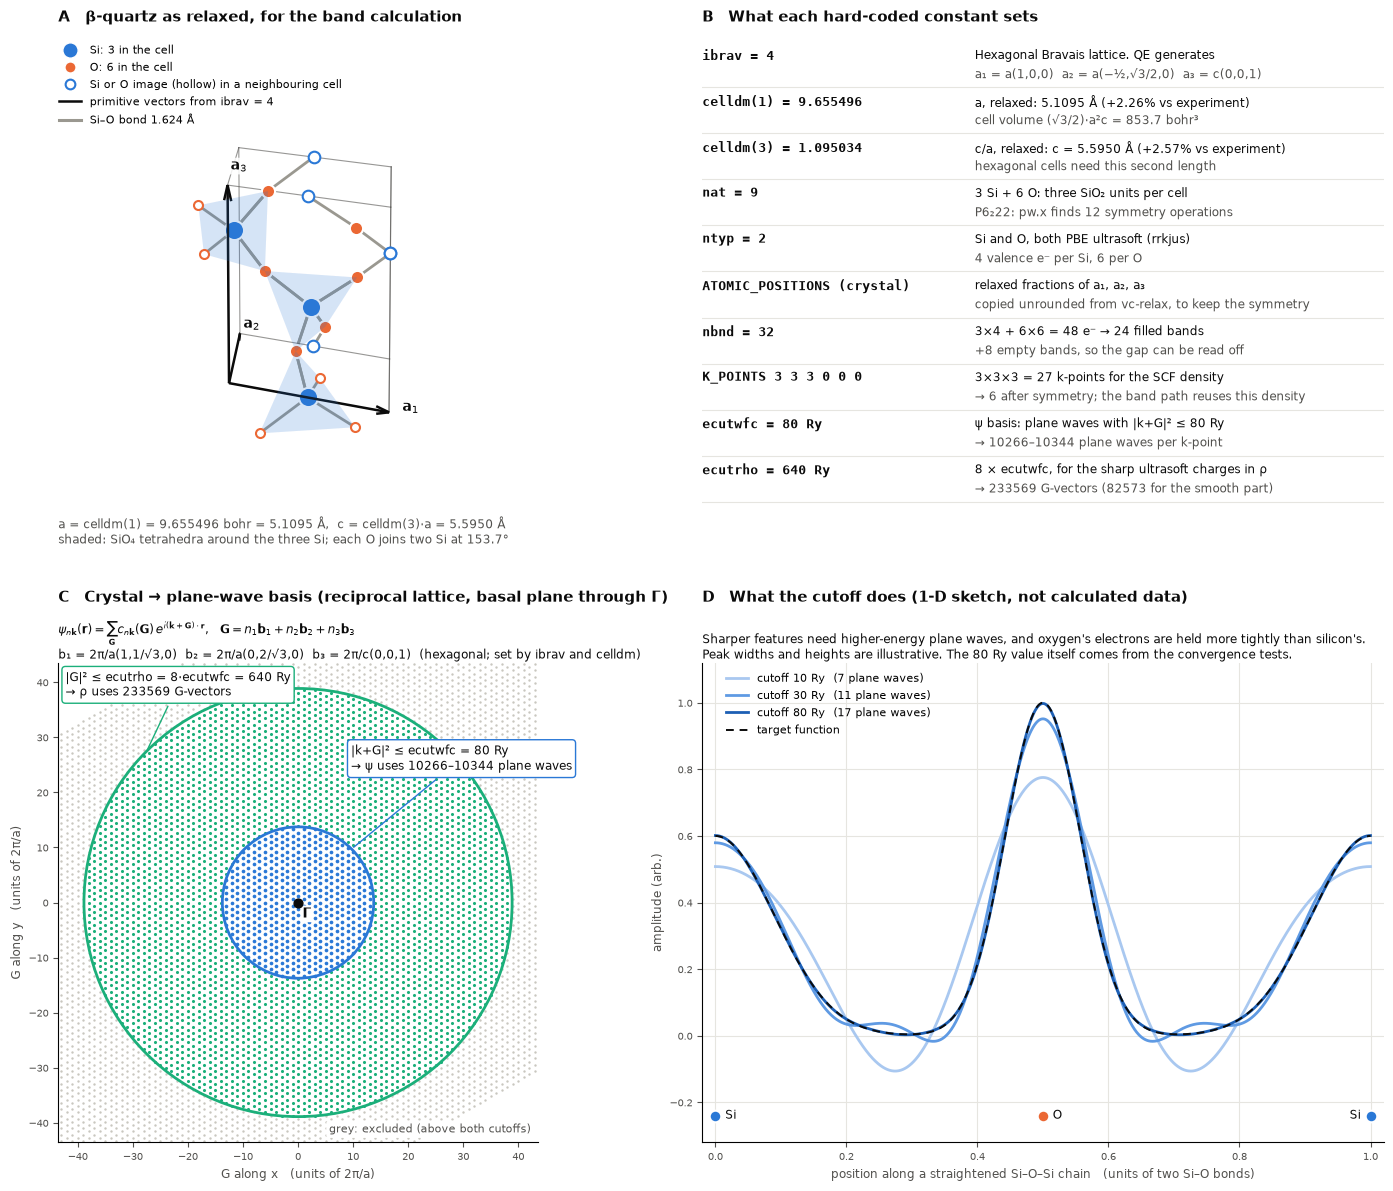

[PASS] figure matches the pw.x output - 6 k-points, 10266-10344 PW/k, 233569 G for rho


In [49]:
import importlib, sio2_figure
importlib.reload(sio2_figure)   # picks up changes to the script without restarting the kernel

fig, pw_counts = sio2_figure.make_sio2_figure("beta", BETA_SCF_INPUT, BETA_SCF_OUT)
plt.show()
check("figure matches the pw.x output", not pw_counts["differences"],
      f"{len(pw_counts['npw_k'])} k-points, {min(pw_counts['npw_k'])}-{max(pw_counts['npw_k'])} PW/k, {pw_counts['n_rho']} G for rho")

### 5.4 NSCF and Density of States

The NSCF run uses a denser k-grid and tetrahedra occupations, and `dos.x` then turns its energies into a density of states.

In [50]:
BETA_NSCF_INPUT = f'''&CONTROL
  calculation= 'nscf',
  restart_mode= 'from_scratch',
  prefix= 'sio2_beta',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {BETA_RELAXED['a']:.6f},
  celldm(3)= {BETA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32,
  occupations= 'tetrahedra'
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{BETA_RELAXED['positions']}

K_POINTS (automatic)
  6 6 6 0 0 0
'''

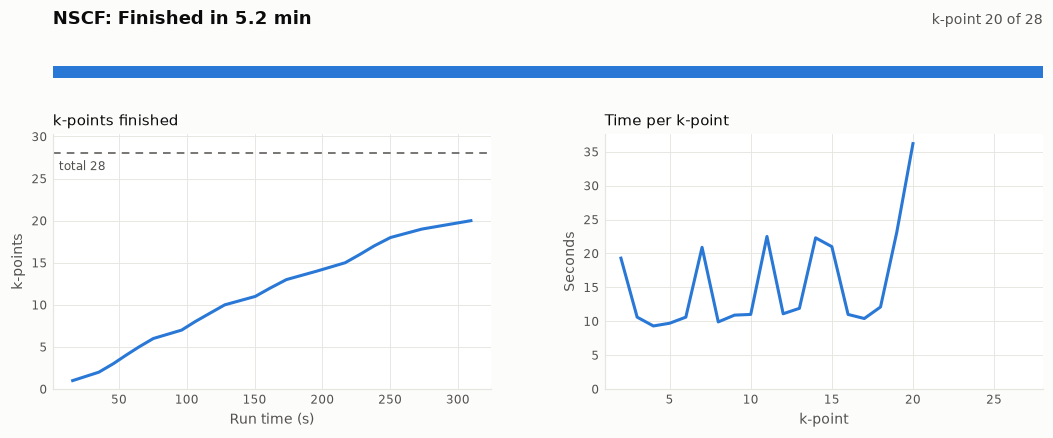

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 310.6 s
[PASS] NSCF finished


In [51]:
BETA_NSCF_OUT = run_pw("pw.nscf.sio2_beta.in", BETA_NSCF_INPUT, BETA_RUN)

In [52]:
BETA_DOS_INPUT = f'''&DOS
  prefix = 'sio2_beta'
  outdir = './tmp/'
  fildos = 'sio2_beta_dos.dat'
  DeltaE = 0.02
/
'''
(BETA_RUN / "pw.dos.sio2_beta.in").write_text(BETA_DOS_INPUT)

# Equivalent of:  dos.x < pw.dos.sio2_beta.in > pw.dos.sio2_beta.out
run_qe(DOS, BETA_RUN / "pw.dos.sio2_beta.in")
check("dos.x wrote data", (BETA_RUN / "sio2_beta_dos.dat").exists())

[PASS] dos.x wrote data


Band gap from the DOS: 5.56 eV


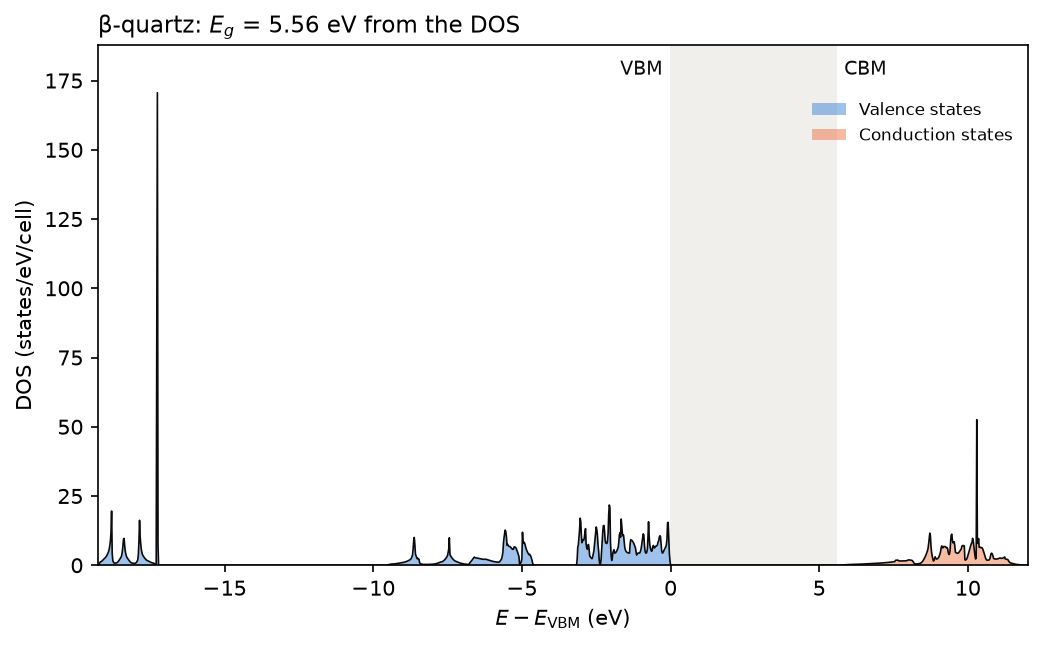

In [53]:
BETA_DOS_GAP = plot_dos(BETA_RUN, "sio2_beta_dos.dat", BETA_NSCF_OUT, "β-quartz")

### 5.5 Band Structure Calculation and Plotting

In [54]:
BETA_BAND_INPUT = f'''&CONTROL
  calculation= 'bands',
  restart_mode= 'from_scratch',
  prefix= 'sio2_beta',
  outdir= './tmp/',
  pseudo_dir= '{PSEUDO_DIR.as_posix()}/',
  verbosity= 'high'
/

&SYSTEM
  ibrav= 4,
  celldm(1)= {BETA_RELAXED['a']:.6f},
  celldm(3)= {BETA_RELAXED['c_over_a']:.6f},
  nat= 9,
  ntyp= 2,
  ecutwfc= 80,
  ecutrho= 640,
  nbnd= 32
/

&ELECTRONS
  conv_thr= 1e-8,
  mixing_beta= 0.5
/

ATOMIC_SPECIES
  Si 28.0855 {SIO2_SI_PSEUDO}
  O 15.999 {SIO2_O_PSEUDO}

ATOMIC_POSITIONS (crystal)
{BETA_RELAXED['positions']}

K_POINTS {{crystal_b}}
8
  0.00000 0.00000 0.00000 14  !G
  0.50000 0.00000 0.00000 8   !M
  0.33333 0.33333 0.00000 16  !K
  0.00000 0.00000 0.00000 11  !G
  0.00000 0.00000 0.50000 14  !A
  0.50000 0.00000 0.50000 8   !L
  0.33333 0.33333 0.50000 16  !H
  0.00000 0.00000 0.50000 1   !A
'''

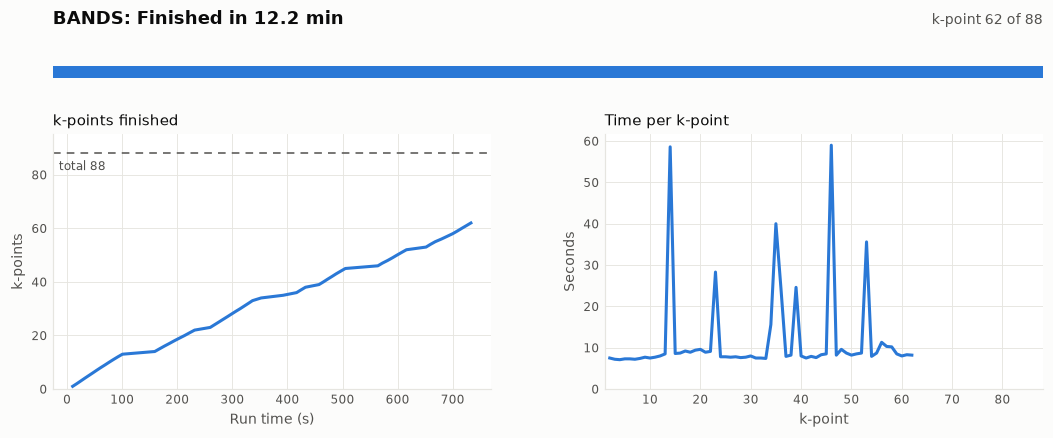

[PASS] pw.x exit code 0 - code 0
[PASS] JOB DONE - 734.0 s
[PASS] Bands finished


In [55]:
BETA_BAND_OUT = run_pw("pw.scf.bg_sio2_beta.in", BETA_BAND_INPUT, BETA_RUN)

In [56]:
# lsym = .false. skips the optional symmetry labels, which crash bands.x for β-quartz
BETA_POST = f'''&BANDS
  prefix = 'sio2_beta'
  outdir = './tmp/'
  filband = 'sio2_beta_bands.dat'
  lsym = .false.
/
'''
(BETA_RUN / "pw.scf.pp_sio2_beta.in").write_text(BETA_POST)

# Equivalent of:  bands.x < pw.scf.pp_sio2_beta.in > pw.scf.pp_sio2_beta.out
run_qe(BANDS, BETA_RUN / "pw.scf.pp_sio2_beta.in")
check("bands.x wrote data", (BETA_RUN / "sio2_beta_bands.dat.gnu").exists())

[PASS] bands.x wrote data


Band gap along this path: 5.53 eV (indirect)
  VBM at Γ–A, CBM at Γ
  Smallest direct gap: 5.72 eV


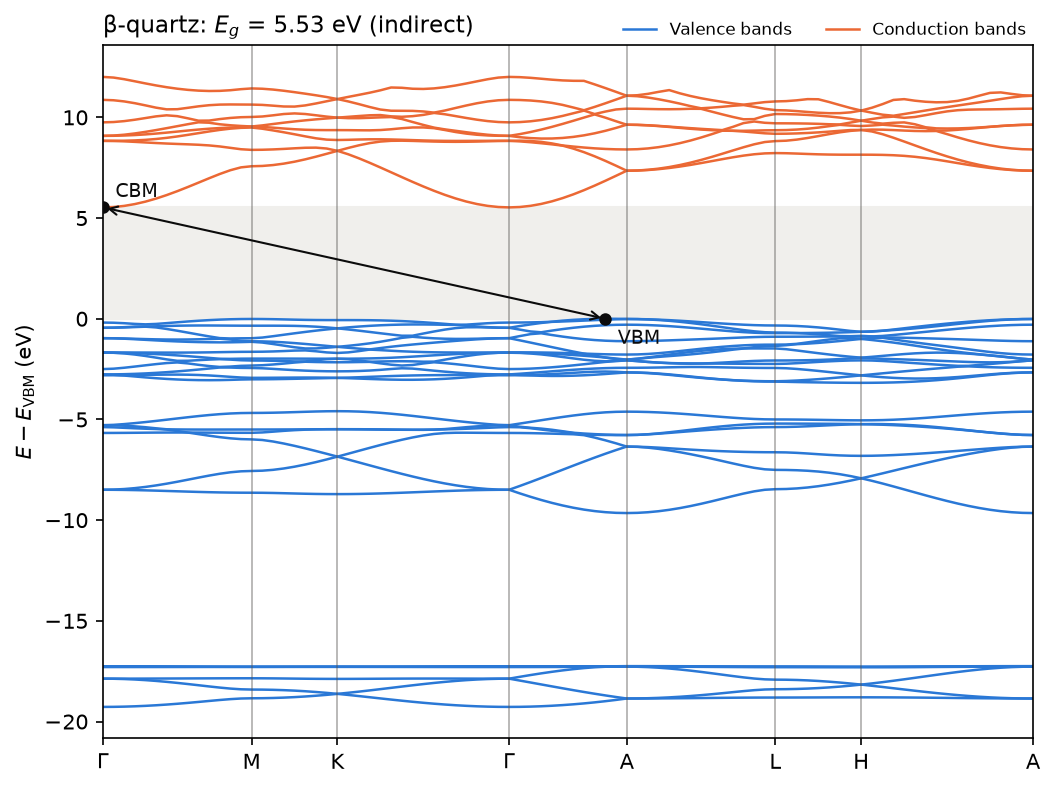

Gap comparison: 5.53 eV from bands, 5.56 eV from the DOS


In [57]:
BETA_GAP = plot_band_gap(BETA_RUN, "sio2_beta_bands.dat", BETA_RUN / "pw.scf.pp_sio2_beta.out", BETA_SCF_OUT,
                        "β-quartz", [r"$\Gamma$", "M", "K", r"$\Gamma$", "A", "L", "H", "A"])
print(f"Gap comparison: {BETA_GAP:.2f} eV from bands, {BETA_DOS_GAP:.2f} eV from the DOS")